# **TRABAJO PRÁCTICO N° 2 - Mineria de Datos**
---
##### 2do. Cuatrimestre - Año 2026

| **Integrantes**           | **Legajo** |
|---------------------------|------------|
| Ruiz, Irma Carolina          | R-4544/6|
| Bartomioli, Ornella  | ?   |

##### **Docentes:** Flavio E. Spetale - Ramiro Gatti - Julieta López Ceratto





In [1]:
# Manejo de datos
import numpy as np
import pandas as pd
import os

# Visualización
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

# Preparación de datos
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Arboles de desición
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor,plot_tree, export_text,export_graphviz
from sklearn.model_selection import train_test_split, RandomizedSearchCV

# Flujo de datos
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

# Métricas
from sklearn.metrics import silhouette_score,silhouette_samples
from sklearn.metrics import (accuracy_score, precision_score, recall_score,f1_score, confusion_matrix, mean_absolute_error,
                             mean_squared_error,classification_report,ConfusionMatrixDisplay,roc_curve, auc)

from sklearn.pipeline import make_pipeline
import itertools

# Clasificador Bayesiano ingenuo
from sklearn.naive_bayes import GaussianNB, BernoulliNB, MultinomialNB

# Clasificador KNN
from sklearn.neighbors import KNeighborsClassifier


## PARTE A
### Regresión (dataset 1000_Companies.csv)

### 1) Limpieza y análisis de los datos.

In [2]:
# Carga y visuaización del dataset sobre las empresas
empresas = pd.read_csv('1000_Companies.csv')
empresas.head()

,RyD_Spend,Administration,MarketingSpend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


In [3]:
empresas.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   RyD_Spend       1000 non-null   float64
 1   Administration  1000 non-null   float64
 2   MarketingSpend  1000 non-null   float64
 3   State           1000 non-null   str    
 4   Profit          1000 non-null   float64
dtypes: float64(4), str(1)
memory usage: 47.4 KB


Se puede observar que el conjunto de datos no presenta datos faltantes. Asimismo, todas las variables son de tipo float, salvo State que es de tipo string.

#### Análisis de Variables:

In [4]:
empresas.describe()

,RyD_Spend,Administration,MarketingSpend,Profit
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,81668.927200,122963.897612,226205.058419,119546.164656
std,46537.567891,12613.927535,91578.393542,42888.633848
min,0.000000,51283.140000,0.000000,14681.400000
25%,43084.500000,116640.684850,150969.584600,85943.198543
50%,79936.000000,122421.612150,224517.887350,117641.466300
75%,124565.500000,129139.118000,308189.808525,155577.107425
max,165349.200000,321652.140000,471784.100000,476485.430000


***RyD_Spend :***

**Media:** 81668.92 | **Mediana:** 79936.00  
Presenta una Media y una Mediana muy similar, lo que se puede asociar a una distribución aparentemente simetrica sin presencia de valores extremos.

**Rango:** 0 – 165349.20  

Su minimo en 0 sugiere que algunas empresas no realizaron inversión en investigación y desarrollo.
**Desviación estándar:** 46537.567

Indica una **variabilidad significativa**.

---
***Administration:***

**Media:** 122963.89 | **Mediana:** 122421.61  
La Media y la Mediana son similares, por lo que sugiere una **distribucion simétrica** pero con colas largas por sus valores mínimos y máximos.

**Rango:** 51283.14 – 321652.14

**Desviación estándar:**  12613.92

---
***MarketingSpend:***

**Media:** 226205.05 | **Mediana:** 224517.88  

**Rango:** 0 – 471784.10

**Desviación estándar:**  91578.39

Muy elevada, sugiere una **gran dispersión**.

---
***Profit:***

**Media:** 119546.16 | **Mediana:** 117641.46  
Con media mayor, lo que indica una **distribución asimétrica**.

**Rango:** 14681.40 – 476485.43.

Se ve la diferencia en rentabilidad de las diferentes empresas.
**Desviación estándar:** 42888.63

Alta desviacion estándar, lo que indica **alta variabilidad**.

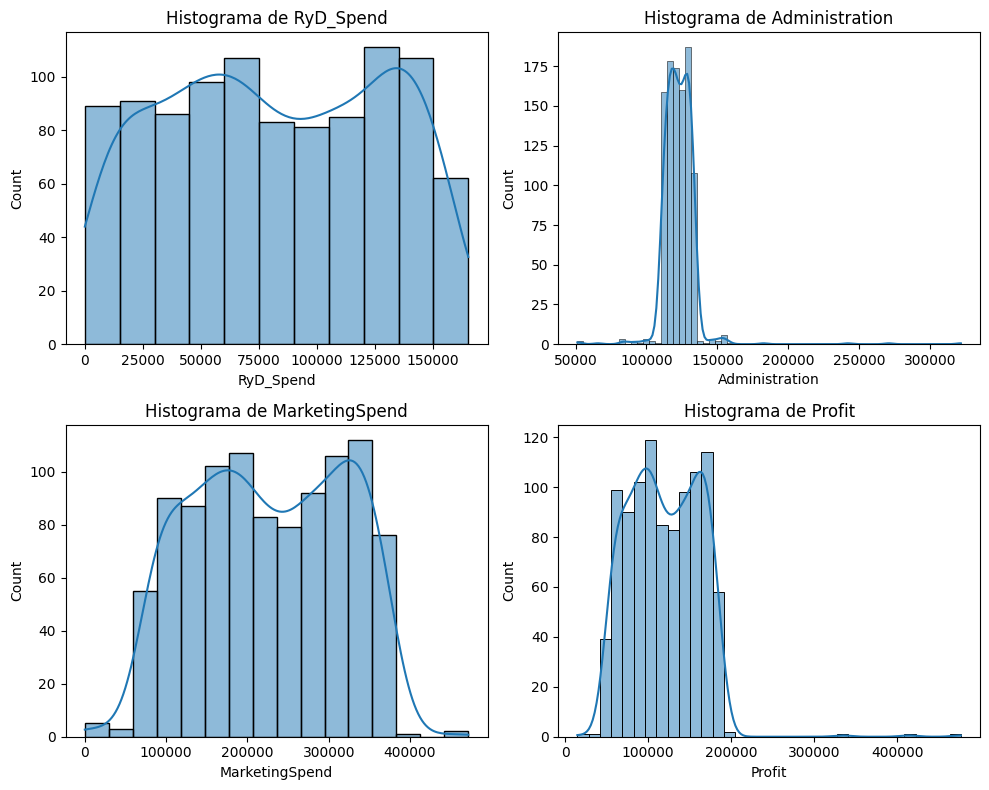

In [5]:
#verificacion de lo analizado anteriormente
cols_num = empresas.select_dtypes(include=['float'])

plt.figure(figsize=(10,8))

for i, col in enumerate(cols_num):
    plt.subplot(2, 2, i+1)
    sns.histplot(empresas[col], kde=True)
    plt.title(f"Histograma de {col}")

plt.tight_layout()
plt.show()

Se confirman las sospechas de colas extensas en Profit y en Administration, sobre todo a la derecha, cosa que ambas comparten, si bien Administration posee a ambos lados.

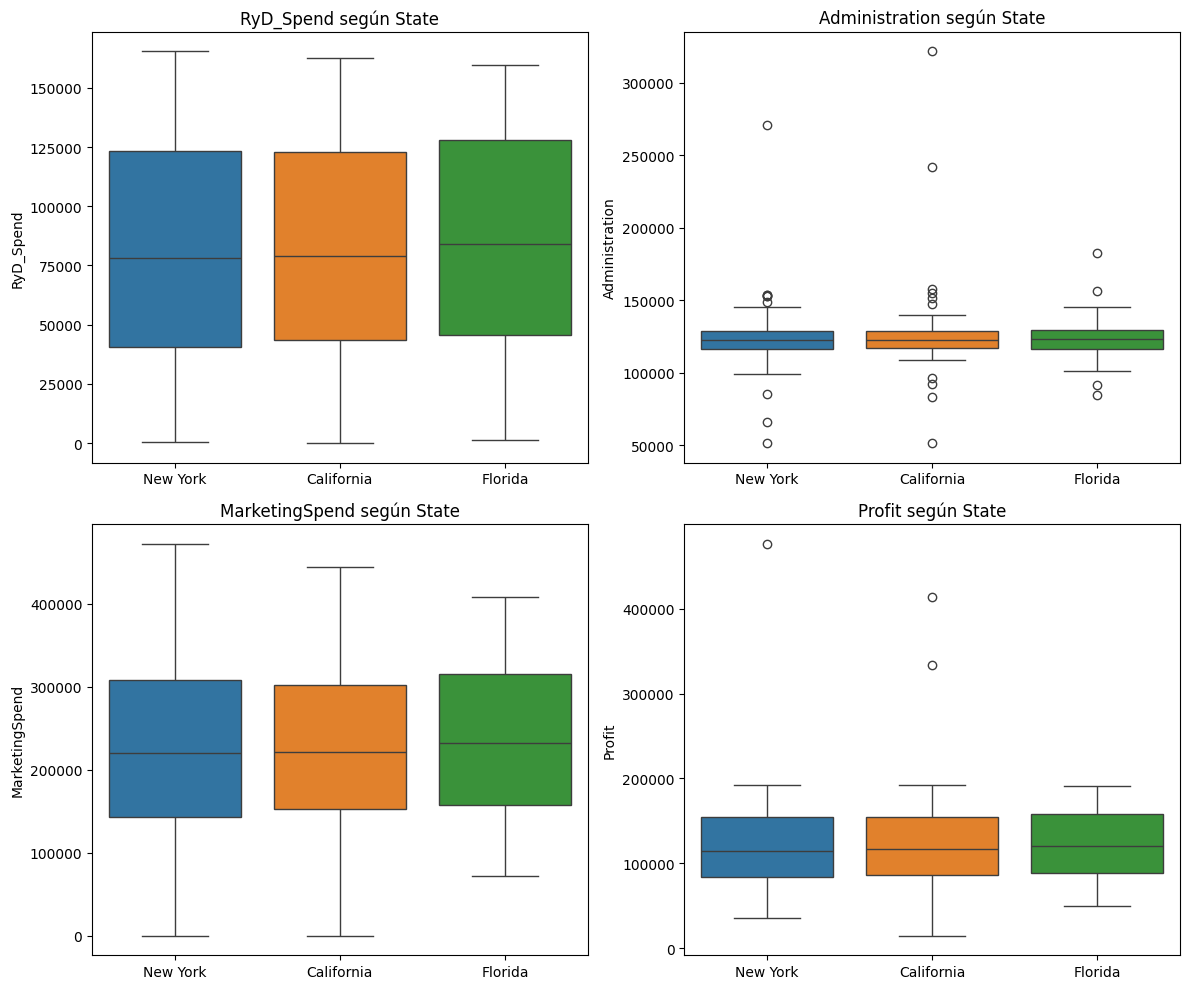

In [6]:
plt.figure(figsize=(12, 10))

for i, col in enumerate(cols_num):
    plt.subplot(2, 2, i+1)
    sns.boxplot(data=empresas, x='State', y=col, hue='State')
    plt.title(f'{col} según State')
    plt.xlabel('')

plt.tight_layout()
plt.show()

Se analizó la distribución de cada variable numérica según State. En los cuatro casos, las medianas y los rangos intercuartiles de New York, California y Florida son muy similares, y los los valores atípicos no se concentran en un único estado. Esto indica que la ubicación de la empresa no se asocia con diferencias en los gastos ni en el Profit, por lo que se decidió no incluir State como variable predictora.

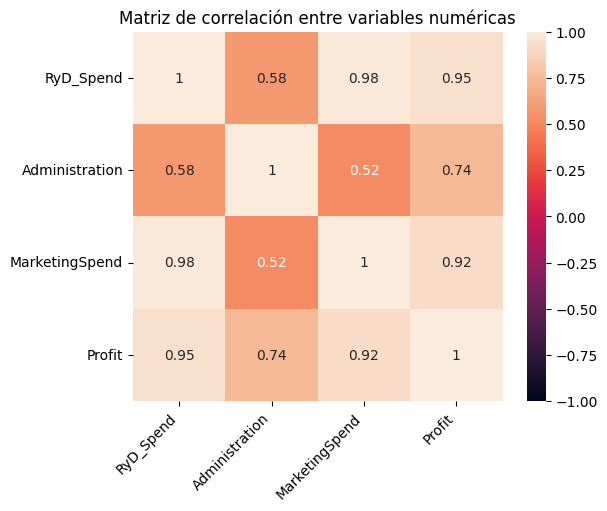

In [7]:
corr = empresas.drop(columns=["State"]).corr()

ax = sns.heatmap(corr,vmin=-1, vmax=1, square=True, annot=True)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, horizontalalignment='right')
plt.title('Matriz de correlación entre variables numéricas')
plt.show()

Profit presenta una correlación muy alta con RyD_Spend (0.95) y MarketingSpend (0.92), y moderada con Administration (0.74), por lo que se espera que RyD_Spend sea la variable más relevante en los cortes del árbol. Además, RyD_Spend y MarketingSpend están muy correlacionadas entre sí (0.98), lo que indica multicolinealidad para un modelo lineal, pero no para un árbol de decisión.

### 2) División Conjuntos Train y Test:

Se realizan la divisiones de los conjuntos de Train y Test. Uno con la proporción 80/20 y otro con la proporción 70/30.

In [8]:
X = empresas[['RyD_Spend', 'Administration', 'MarketingSpend']]
y = empresas['Profit']
X_train_80, X_test_20, y_train_80, y_test_20 = train_test_split(X, y, test_size=0.2, random_state=63)

print(f"Datos de entrenamiento: {X_train_80.shape} y de test: {X_test_20.shape}")

Datos de entrenamiento: (800, 3) y de test: (200, 3)


In [9]:
X_train_70, X_test_30, y_train_70, y_test_30 = train_test_split(X, y, test_size=0.3, random_state=63)

print(f"Datos de entrenamiento: {X_train_70.shape} y de test: {X_test_30.shape}")

Datos de entrenamiento: (700, 3) y de test: (300, 3)


#### Observación y tratamiento de outliers

No se estandarizaron las variables predictoras, ya que los árboles de decisión dividen cada variable por umbrales y no se ven afectados por la escala. Sin embargo, en el análisis exploratorio se observaron valores atípicos en la variable objetivo Profit. Dado que el árbol de regresión predice el promedio de cada hoja, estos valores pueden distorsionar sus predicciones. Por ello, se identifican mediante el criterio Q3 + 1,5·IQR, calculado sobre cada conjunto de entrenamiento.

In [10]:
Q1, Q3 = y_train_80.quantile([0.25, 0.75])
IQR = Q3 - Q1
lim_sup_80_20 = Q3 + 1.5 * IQR
print(f'Límite superior, div. 80-20: {lim_sup_80_20:.2f}')

X_train_80[y_train_80 > lim_sup_80_20].assign(Profit=y_train_80[y_train_80 > lim_sup_80_20])

Límite superior, div. 80-20: 257787.11


,RyD_Spend,Administration,MarketingSpend,Profit
998,128456.23,321652.14,281692.32,333962.19
997,100275.47,241926.31,227142.82,413956.48


In [11]:
Q1, Q3 = y_train_70.quantile([0.25, 0.75])
IQR = Q3 - Q1
lim_sup_70_30 = Q3 + 1.5 * IQR
print(f'Límite superior, div. 70-30: {lim_sup_70_30:.2f}')

X_train_70[y_train_70 > lim_sup_70_30].assign(Profit=y_train_70[y_train_70 > lim_sup_70_30])

Límite superior, div. 70-30: 259600.02


,RyD_Spend,Administration,MarketingSpend,Profit
998,128456.23,321652.14,281692.32,333962.19
997,100275.47,241926.31,227142.82,413956.48


En ambas particiones se identificaron las mismas dos empresas. Para evaluar si estos valores son coherentes con el resto de los datos, se compara su Profit con el Profit mediano de empresas con un nivel de inversión en RyD_Spend similar.

In [12]:
for idx in [997, 998]:
    ryd = X_train_80.loc[idx, 'RyD_Spend']
    similares = y_train_80[(X_train_80['RyD_Spend'] - ryd).abs() < 10000]
    print(f"Empresa {idx}: RyD = {ryd:.0f} | Profit = {y_train_80[idx]:.0f} | "
          f"Profit mediano de empresas similares = {similares.median():.0f}")

Empresa 997: RyD = 100275 | Profit = 413956 | Profit mediano de empresas similares = 136633
Empresa 998: RyD = 128456 | Profit = 333962 | Profit mediano de empresas similares = 159613


Empresa 997: Profit de 413.956, frente a un Profit mediano de 136.633 en empresas similares (aprox. 3 veces mayor).
Empresa 998: Profit de 333.962, frente a un Profit mediano de 159.613 en empresas similares (aprox. 2 veces mayor).

Estos valores no se explican por la inversión de las empresas y, además, ambas presentan valores extremos en Administration, lo que sugiere observaciones anómalas o errores de carga. Dada esta situación, se eliminan del conjunto de entrenamiento esas dos observaciones (menos del 0,3% del conjunto de entrenamiento). El conjunto de test no se modifica.

In [13]:
X_train_80 = X_train_80[y_train_80 <= lim_sup_80_20]
y_train_80 = y_train_80[y_train_80 <= lim_sup_80_20]

X_train_70 = X_train_70[y_train_70 <= lim_sup_70_30]
y_train_70 = y_train_70[y_train_70 <= lim_sup_70_30]

print(f"80/20 → train: {X_train_80.shape}, {y_train_80.shape}")
print(f"70/30 → train: {X_train_70.shape}, {y_train_70.shape}")

80/20 → train: (798, 3), (798,)
70/30 → train: (698, 3), (698,)


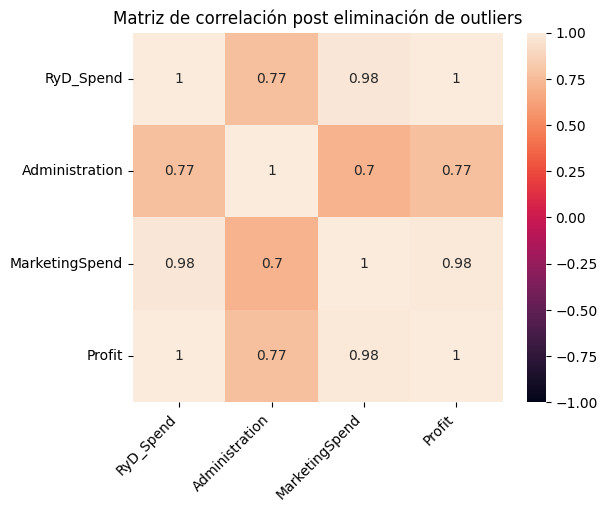

In [14]:
corr = X_train_80.assign(Profit=y_train_80).corr()
ax = sns.heatmap(corr,vmin=-1, vmax=1, square=True, annot=True)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, horizontalalignment='right')
plt.title('Matriz de correlación post eliminación de outliers')
plt.show()

Al comparar la matriz de correlación del dataset completo con la del conjunto de entrenamiento 80/20 sin los outliers removidos, se observa que todas las correlaciones aumentaron o se mantuvieron. Las relaciones de Profit con RyD_Spend (de 0.95 a prácticamente 1) y con MarketingSpend (de 0.92 a 0.98) se fortalecen, y los cambios más marcados se dan en Administration, cuya correlación con RyD_Spend y MarketingSpend sube cerca de 0.2 puntos. Esto confirma que las observaciones eliminadas no seguían el patrón general de los datos y debilitaban las relaciones entre variables.

### 3) Árbol de decisión para regresión:

#### Conjunto 80/20:

a) Variando la profundidad del árbol (**max_deph**):

In [15]:
profundidades = [2, 6, 10, 14]

resultados = []

for prof in profundidades:

    tree_reg = DecisionTreeRegressor(max_depth=prof,criterion='squared_error',min_samples_leaf=1,min_samples_split=2,random_state=63)

    # Entrenamiento
    tree_reg.fit(X_train_80, y_train_80)

    # Predicciones
    y_pred = tree_reg.predict(X_test_20)

    # Métricas
    mae = round(mean_absolute_error(y_test_20, y_pred), 2)
    mse = round(mean_squared_error(y_test_20, y_pred), 2)
    rmse = round(np.sqrt(mse), 2)

    resultados.append({'max_depth': prof,'MAE': mae,'MSE': mse,'RMSE': rmse})

resultados_empresas1 = pd.DataFrame(resultados)
display(resultados_empresas1)

,max_depth,MAE,MSE,RMSE
0,2,10485.95,5.812224e+08,24108.55
1,6,2692.92,4.328169e+08,20804.25
2,10,2166.03,4.401294e+08,20979.26
3,14,2105.84,4.301543e+08,20740.16


Observaciones:

...

b) Variando el número mínimo de observaciones por hoja (**min_samples_leaf**) :

In [16]:
observaciones = [1, 3, 5]

resultados = []

for obs in observaciones:

    tree_reg = DecisionTreeRegressor(max_depth=14,criterion='squared_error',min_samples_leaf=obs,min_samples_split=2,random_state=63)

    # Entrenamiento
    tree_reg.fit(X_train_80, y_train_80)

    # Predicciones
    y_pred = tree_reg.predict(X_test_20)

    # Métricas
    mae = round(mean_absolute_error(y_test_20, y_pred), 2)
    mse = round(mean_squared_error(y_test_20, y_pred), 2)
    rmse = round(np.sqrt(mse), 2)

    resultados.append({'min_samples_leaf': obs,'MAE': mae,'MSE': mse,'RMSE': rmse})

resultados_empresas1 = pd.DataFrame(resultados)
display(resultados_empresas1)

,min_samples_leaf,MAE,MSE,RMSE
0,1,2105.84,4.301543e+08,20740.16
1,3,2337.60,4.420906e+08,21025.95
2,5,2428.37,4.331454e+08,20812.15


Observaciones:

...

c) Variando el número mínimo de observaciones para realizar una separación (**min_samples_split**):

In [17]:
observaciones = [2, 5, 10, 15, 20]

resultados = []

for obs in observaciones:

    tree_reg = DecisionTreeRegressor(max_depth=14,criterion='squared_error',min_samples_leaf=1,min_samples_split=obs,random_state=63)

    # Entrenamiento
    tree_reg.fit(X_train_80, y_train_80)

    # Predicciones
    y_pred = tree_reg.predict(X_test_20)

    # Métricas
    mae = round(mean_absolute_error(y_test_20, y_pred), 2)
    mse = round(mean_squared_error(y_test_20, y_pred), 2)
    rmse = round(np.sqrt(mse), 2)

    resultados.append({'min_samples_split': obs,'MAE': mae,'MSE': mse,'RMSE': rmse})

resultados_empresas1 = pd.DataFrame(resultados)
display(resultados_empresas1)

,min_samples_split,MAE,MSE,RMSE
0,2,2105.84,4.301543e+08,20740.16
1,5,2217.57,4.312123e+08,20765.65
2,10,2392.22,4.602612e+08,21453.70
3,15,2641.15,4.601767e+08,21451.73
4,20,2610.65,4.334907e+08,20820.44


Observaciones:

...

#### d) Visualización del árbol seleccionado:

In [21]:
tree_reg1 = DecisionTreeRegressor(max_depth=14, min_samples_leaf=1, min_samples_split=2,
                                  criterion='squared_error', random_state=63)
# Entrenamiento
tree_reg1.fit(X_train_80, y_train_80)

,"criterion criterion: {""squared_error"", ""friedman_mse"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in the half mean Poisson deviance to find splits... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",14
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",63
,"max_lea

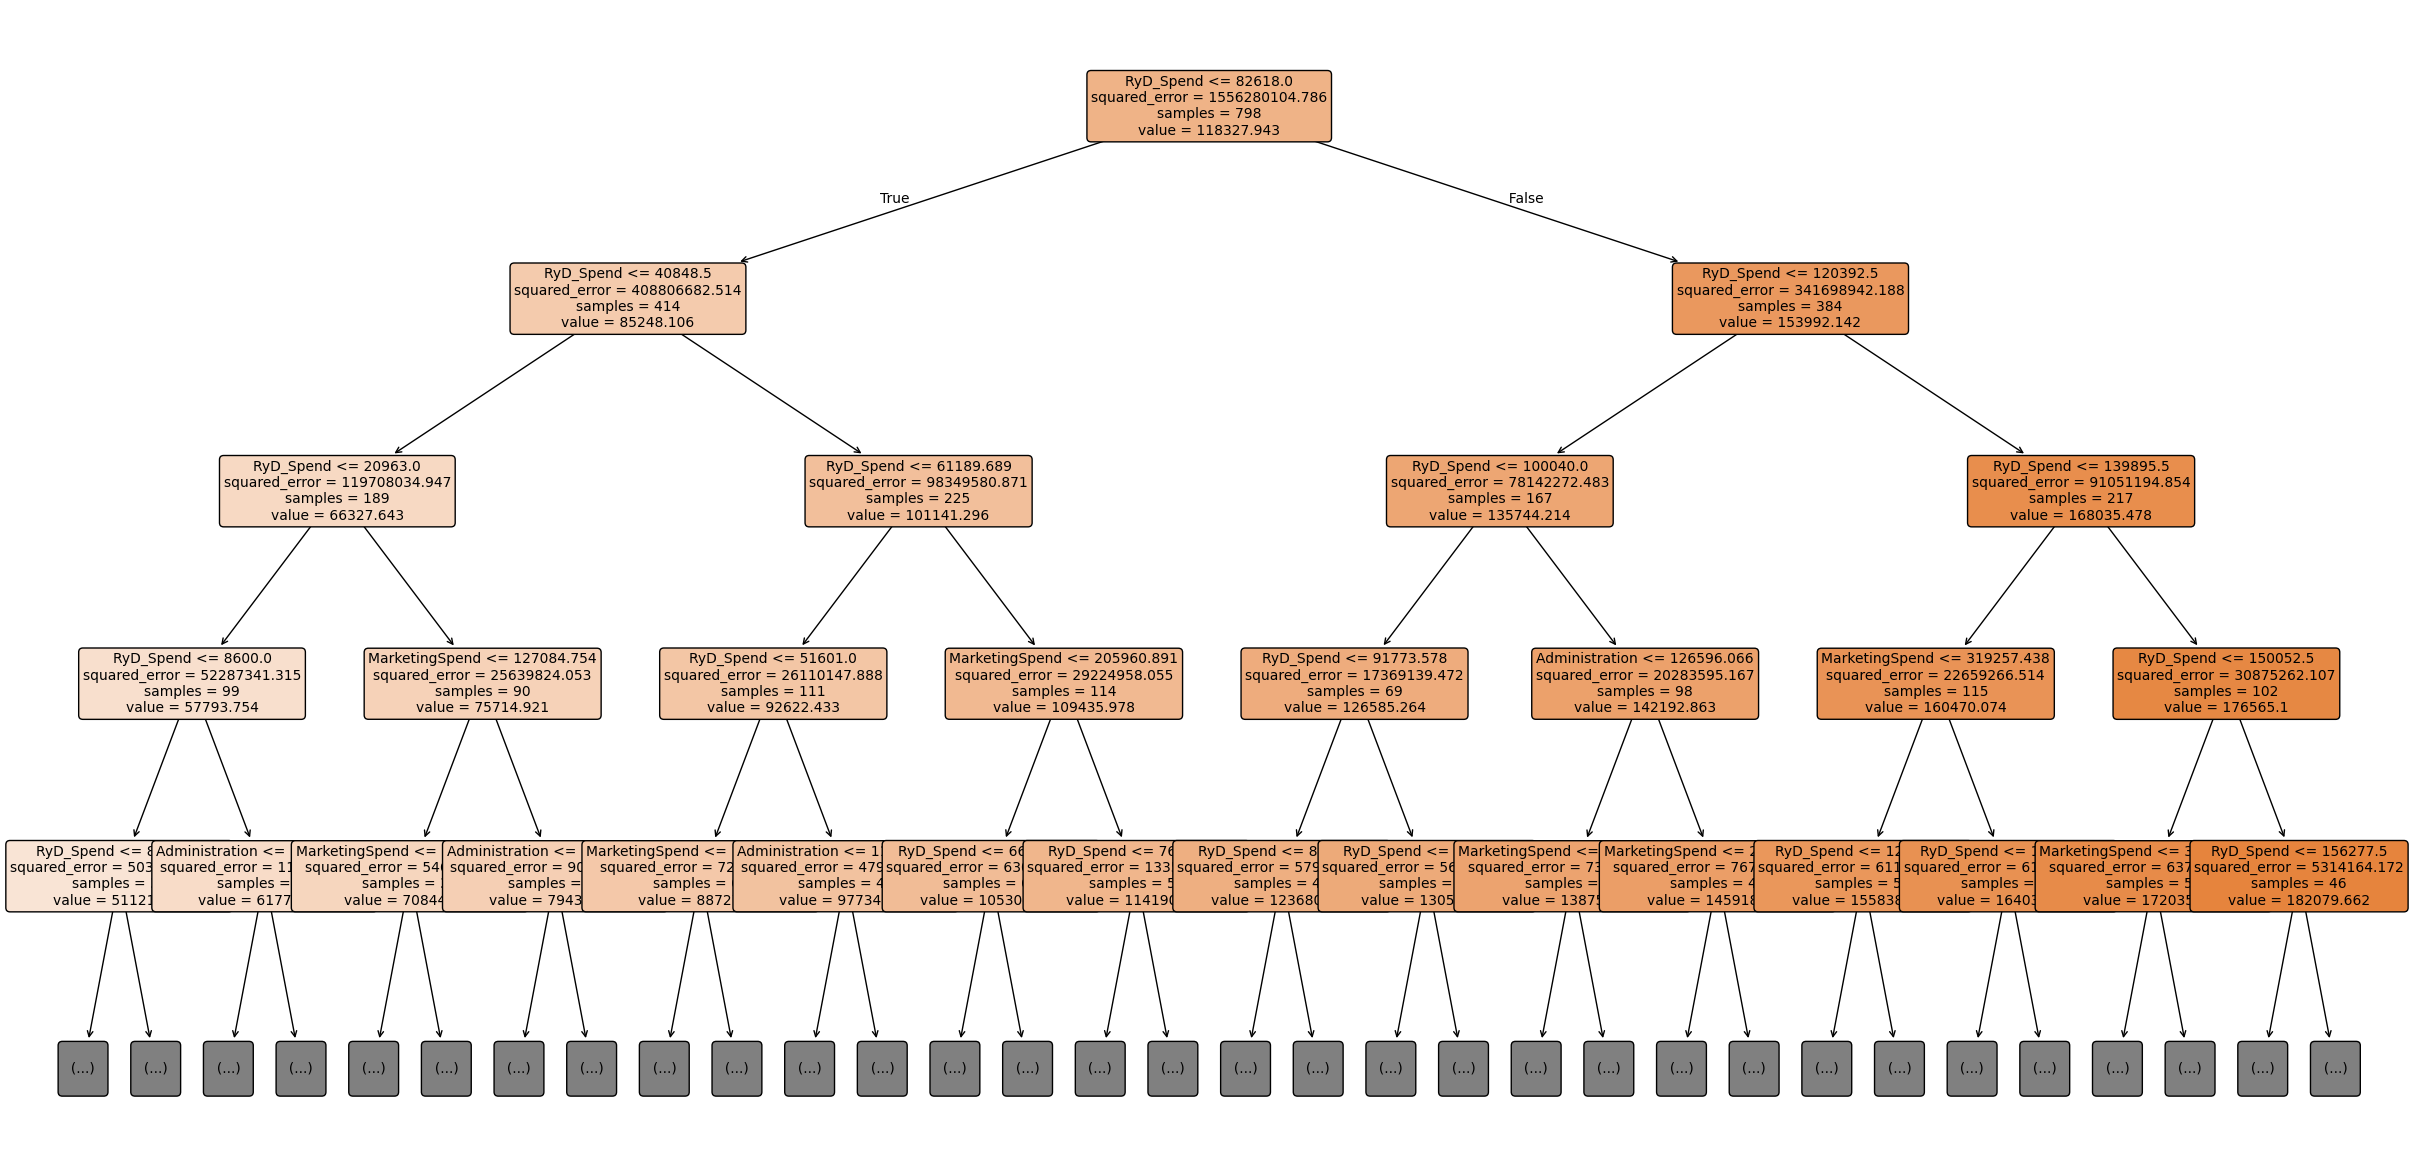

In [22]:
plt.figure(figsize=(30,15))
plot_tree(tree_reg1,feature_names=X_train_80.columns,filled=True,rounded=True,fontsize=10,max_depth=4)
plt.show()

---

### Conjunto 70/30:

In [ ]:
#Separamos variables predictoras y objetivo:
X2_train = empresas2_train[['RyD_Spend',	'Administration',	'MarketingSpend']]
y2_train = empresas2_train['Profit']

X2_test = empresas2_test[['RyD_Spend',	'Administration',	'MarketingSpend']]
y2_test = empresas2_test['Profit']

#### a) Variando la profundidad del árbol ('max_deph'):

In [ ]:
profundidades = [2, 4, 6, 8, 10]

resultados = []

for prof in profundidades:

    tree_reg = DecisionTreeRegressor(max_depth=prof,criterion='squared_error',min_samples_leaf=1,min_samples_split=2,random_state=63)

    # Entrenamiento
    tree_reg.fit(X2_train, y2_train)

    # Predicciones
    y_pred = tree_reg.predict(X2_test)

    # Métricas
    mae = mean_absolute_error(y2_test, y_pred)
    mse = mean_squared_error(y2_test, y_pred)
    rmse = np.sqrt(mse)

    resultados.append({'max_depth': prof,'MAE': mae,'MSE': mse,'RMSE': rmse})

resultados_empresas1 = pd.DataFrame(resultados)
display(resultados_empresas1)

,max_depth,MAE,MSE,RMSE
0,2,9697.010637,4.167923e+08,20415.491950
1,4,3643.406333,3.008392e+08,17344.717505
2,6,2109.908035,2.909924e+08,17058.500645
3,8,1612.609723,2.942365e+08,17153.324376
4,10,1677.353597,2.996283e+08,17309.774240


Se determinó que el valor óptimo es max_depth = 6, ya que presenta el menor RMSE. A partir de profundidades mayores se observa un aumento del error, indicando posible sobreajuste. Por ello, la profundidad 6 ofrece el mejor equilibrio entre precisión y capacidad de generalización.

#### b) Variando el número mínimo de observaciones por hoja (min_samples_leaf) :

In [ ]:
observaciones = [1,2,3, 5,7, 10]

resultados = []

for obs in observaciones:

    tree_reg = DecisionTreeRegressor(max_depth=6,criterion='squared_error',min_samples_leaf=obs,min_samples_split=2,random_state=63)

    # Entrenamiento
    tree_reg.fit(X2_train, y2_train)

    # Predicciones
    y_pred = tree_reg.predict(X2_test)

    # Métricas
    mae = mean_absolute_error(y2_test, y_pred)
    mse = mean_squared_error(y2_test, y_pred)
    rmse = np.sqrt(mse)

    resultados.append({'min_samples_leaf': obs,'MAE': mae,'MSE': mse,'RMSE': rmse})

resultados_empresas1 = pd.DataFrame(resultados)
display(resultados_empresas1)

,min_samples_leaf,MAE,MSE,RMSE
0,1,2109.908035,2.909924e+08,17058.500645
1,2,2051.664126,2.971326e+08,17237.535629
2,3,2097.419852,2.993946e+08,17303.022143
3,5,2078.751059,2.981546e+08,17267.153846
4,7,2138.930373,3.073369e+08,17531.026034
5,10,2250.821736,2.997073e+08,17312.056227


Fijando max_depth = 6, seleccionamos min_samples_leaf = 1, ya que presenta el menor MAE y valores de RMSE similares al mínimo observado. Aunque configuraciones con valores mayores logran reducciones minimas en RMSE, el incremento del error absoluto medio indica una menor precisión promedio en las predicciones.

#### c) Variando el número mínimo de observaciones para realizar una separación (min_samples_split):

In [ ]:
observaciones = [2, 5, 10, 15, 20]

resultados = []

for obs in observaciones:

    tree_reg = DecisionTreeRegressor(max_depth=6,criterion='squared_error',min_samples_leaf=1,min_samples_split=obs,random_state=63)

    # Entrenamiento
    tree_reg.fit(X2_train, y2_train)

    # Predicciones
    y_pred = tree_reg.predict(X2_test)

    # Métricas
    mae = mean_absolute_error(y2_test, y_pred)
    mse = mean_squared_error(y2_test, y_pred)
    rmse = np.sqrt(mse)

    resultados.append({'min_samples_split': obs,'MAE': mae,'MSE': mse,'RMSE': rmse})

resultados_empresas1 = pd.DataFrame(resultados)
display(resultados_empresas1)

,min_samples_split,MAE,MSE,RMSE
0,2,2109.908035,2.909924e+08,17058.500645
1,5,2114.553314,2.974569e+08,17246.937861
2,10,2114.553314,2.974569e+08,17246.937861
3,15,2186.622915,3.070295e+08,17522.258532
4,20,2246.965880,3.010800e+08,17351.655602


Para el hiperparámetro min_samples_split, seleccionamos el valor 2, ya que obtuvo el menor MAE y RMSE de la comparación.

#### d) Visualización del árbol seleccionado

In [ ]:
tree_reg2 = DecisionTreeRegressor(max_depth=6,min_samples_leaf=1,min_samples_split=2,criterion='squared_error',random_state=63)

# Entrenamiento
tree_reg2.fit(X2_train, y2_train)

DecisionTreeRegressor(max_depth=6, random_state=63)

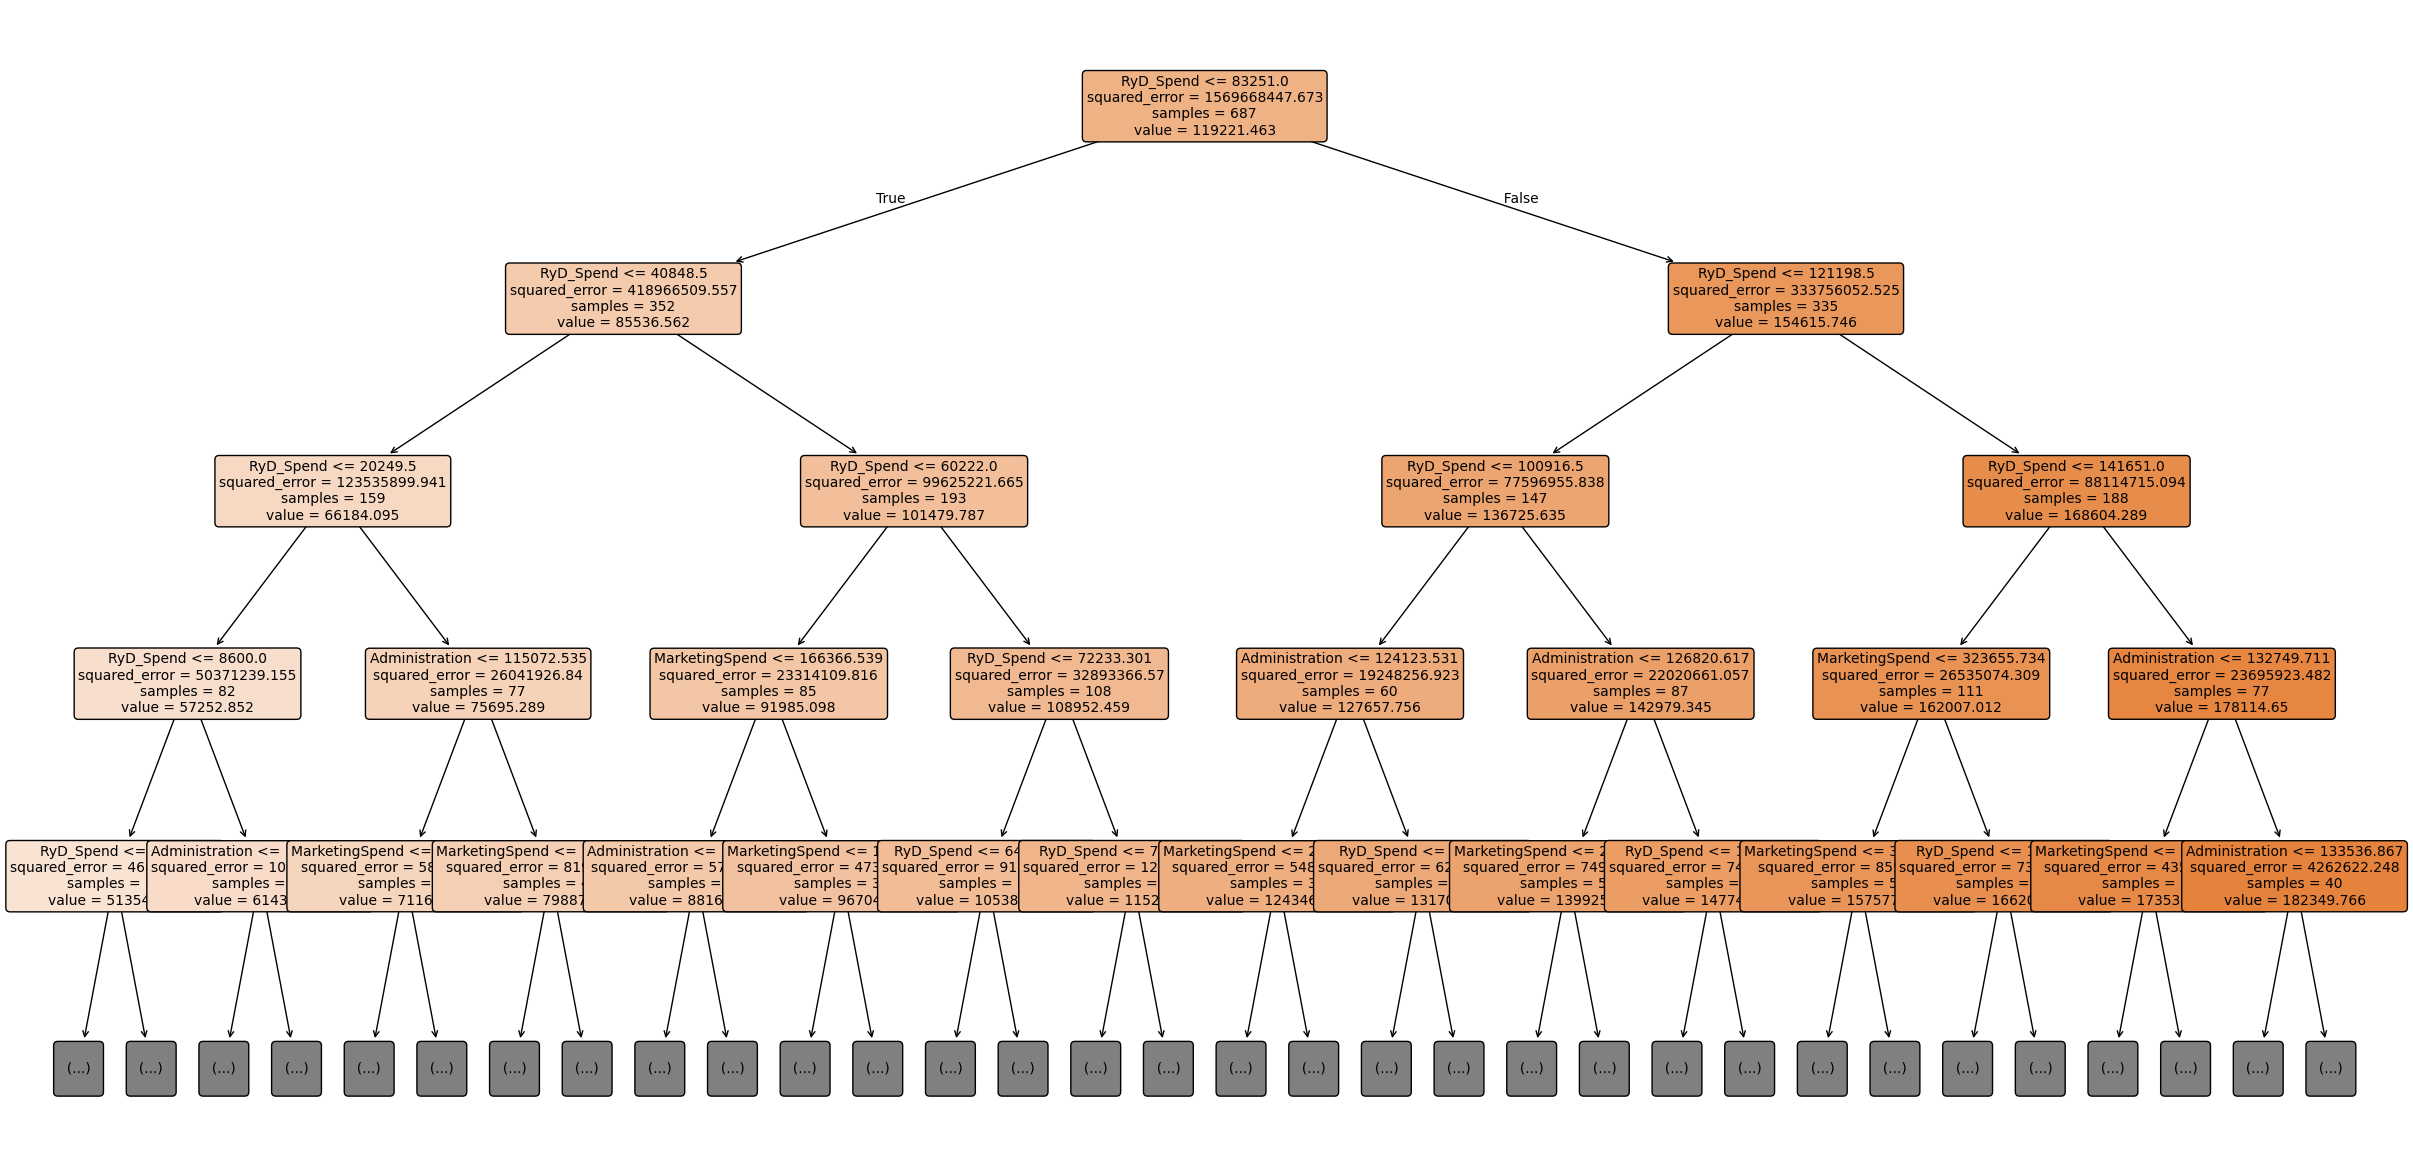

In [ ]:
plt.figure(figsize=(30,15))
plot_tree(tree_reg2,feature_names=X2_train.columns,filled=True,rounded=True,fontsize=10,max_depth=4)
plt.show()

##5) CONCLUSION:

In [ ]:
resultados_finales = []

# Modelo 80/20
tree_reg1 = DecisionTreeRegressor(max_depth=8,min_samples_leaf=5,min_samples_split=2,criterion='squared_error',random_state=63)
tree_reg1.fit(X1_train, y1_train)
pred1 = tree_reg1.predict(X1_test)

mae1 = mean_absolute_error(y1_test, pred1)
mse1 = mean_squared_error(y1_test, pred1)
rmse1 = np.sqrt(mse1)

resultados_finales.append({'Modelo': '80/20','MAE': mae1,'MSE': mse1,'RMSE': rmse1})

# Modelo 70/30
tree_reg2 = DecisionTreeRegressor(max_depth=6,min_samples_leaf=1,min_samples_split=2,criterion='squared_error',random_state=63)
tree_reg2.fit(X2_train, y2_train)
pred2 = tree_reg2.predict(X2_test)

mae2 = mean_absolute_error(y2_test, pred2)
mse2 = mean_squared_error(y2_test, pred2)
rmse2 = np.sqrt(mse2)

resultados_finales.append({'Modelo': '70/30','MAE': mae2,'MSE': mse2,'RMSE': rmse2})


comparacion = pd.DataFrame(resultados_finales)
display(comparacion.round(2))

,Modelo,MAE,MSE,RMSE
0,80/20,2550.89,4.408474e+08,20996.37
1,70/30,2109.91,2.909924e+08,17058.50


El modelo 70/30 mostró un mejor desempeño general. Esto sugiere una mejor capacidad predictiva y una mayor estabilidad en las estimaciones de Profit para esta partición de los datos.

---

# PARTE B - Clasificación (dataset drugType.csv)

## Funciones auxiliares

In [ ]:
def target_balance(df, target):
    """Visualizar el balance de clases"""
    cantidad = df[target].value_counts()
    porcentaje = df[target].value_counts(normalize=True) * 100

    balance = pd.DataFrame({
        'Cantidad': cantidad,
        'Porcentaje': porcentaje.map('{:.0f}%'.format)
    })

    print(f"Balance de '{target}':")
    print(balance.to_markdown(numalign="left", stralign="left",
                              tablefmt="simple"))

def tableResult(label, prediction):
    """Visualizar resultados"""
    print("\n-------------- Reporte --------------")
    print(classification_report(label, prediction))

    # Confusion Matrix
    cm = confusion_matrix(label, prediction)
    plt.figure(figsize=(8, 6))

    class_labels = sorted(label.unique())

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_labels,
                yticklabels=class_labels,
                cbar=False)
    plt.xlabel('Predicción')
    plt.ylabel('Real')
    plt.title('Matriz de confusión')
    plt.show()

def discretizar(datos_train, datos_test, columnas, n_bins):
    """
    Discretiza por frecuencia igual usando los límites del Train para el Test.
    """

    datos_train = datos_train.copy()
    datos_test = datos_test.copy()

    for col in columnas:
        #  Calculamos los bins en el TRAIN
        _, bins = pd.qcut(datos_train[col], q=n_bins, retbins=True, labels=False, duplicates='drop')

        # Extender extremos para cubrir cualquier valor del test
        bins[0] = -np.inf
        bins[-1] = np.inf

        #  Aplicamos esos bins al TRAIN
        datos_train[f'{col}_disc'] = pd.cut(datos_train[col], bins=bins, labels=False, include_lowest=True)

        #  Aplicamos esos mismos bins al TEST
        datos_test[f'{col}_disc'] = pd.cut(datos_test[col], bins=bins, labels=False, include_lowest=True)

    return datos_train, datos_test

## 1) Limpieza y análisis de los datos.

In [ ]:
# Carga y visuaización del conjunto de Datos sobre drogas farmacéuticas.
farmac = pd.read_csv('/content/drugType.csv')
farmac.head()

,Edad,Sexo,BP,Colesterol,Na_a_K,Droga
0,23,F,Alto,Alto,25.355,DrogaY
1,47,M,Bajo,Alto,13.093,DrogaC
2,47,M,Bajo,Alto,10.114,DrogaC
3,28,F,Normal,Alto,7.798,DrogaX
4,61,F,Bajo,Alto,18.043,DrogaY


In [ ]:
farmac.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Edad        200 non-null    int64  
 1   Sexo        200 non-null    object 
 2   BP          200 non-null    object 
 3   Colesterol  200 non-null    object 
 4   Na_a_K      200 non-null    float64
 5   Droga       200 non-null    object 
dtypes: float64(1), int64(1), object(4)
memory usage: 9.5+ KB


Se puede observar que el conjunto de datos no presenta datos faltantes.

Análisis de Variables:

In [ ]:
farmac.describe()

,Edad,Na_a_K
count,200.000000,200.000000
mean,44.315000,16.084485
std,16.544315,7.223956
min,15.000000,6.269000
25%,31.000000,10.445500
50%,45.000000,13.936500
75%,58.000000,19.380000
max,74.000000,38.247000


***Edad :***

**Media:** 44.31 | **Mediana:** 45  
Presenta una Media y una Mediana muy similar, lo que se puede asociar a una distribución aparentemente simetrica sin presencia de valores extremos.

**Rango:** 15 – 74  

**Desviación estándar:** 16.54


---
***Na_a_K:***

**Media:** 16.08 | **Mediana:** 13.93  
La Media y la Mediana son iguales, por lo que sugiere una distribucion simetrica.

**Rango:** 6.26 – 38.24

**Desviación estándar:**  7.22

In [ ]:
# Lista columnas categóricas
col_cat = ['Sexo','BP','Colesterol','Droga']

for col in col_cat:
    print(f"Valores únicos en {col}: {farmac[col].unique()}")

Valores únicos en Sexo: ['F' 'M']
Valores únicos en BP: ['Alto' 'Bajo' 'Normal']
Valores únicos en Colesterol: ['Alto' 'Normal']
Valores únicos en Droga: ['DrogaY' 'DrogaC' 'DrogaX' 'DrogaA' 'DrogaB']


***Sexo :***

**Valores:** F -M

---
***BP:***

**Valores:** Bajo - Normal - Alto

---
***Colesterol:***

**Valores:** Normal - Alto  

---
***Drogra:***

**Valores:** DrogaA - DrogaB - DrogaC- DrogaX - DrogaY



In [ ]:
farmac["Sexo_cod"] = farmac["Sexo"].map({'F':1, 'M':0})
farmac['BP_cod'] = farmac['BP'].map({'Alto':2,'Normal':1,'Bajo':0})
farmac['Colesterol_cod'] = farmac['Colesterol'].map({'Alto':1,'Normal':0})
farmac['Droga_cod'] = farmac['Droga'].map({'DrogaA':0, 'DrogaB':1, 'DrogaC':2, 'DrogaX':3,'DrogaY':4})

##2) División Conjuntos Train y Test:

Realizamos la división de los conjuntos de Train y Test. Uno con la proporción 80/20 y otro con la proporción 70/30.

In [ ]:
# Proporción 80/20:
farmac1_train, farmac1_test = train_test_split(farmac,test_size=0.2,random_state=63,stratify=farmac['Droga'])

farmac1_train = farmac1_train.copy(deep=True)
farmacs1_test = farmac1_test.copy(deep=True)

print(f'Los datos de entranamiento son: {farmac1_train.shape} y los de test: {farmac1_test.shape}')

Los datos de entranamiento son: (160, 10) y los de test: (40, 10)


In [ ]:
# Proporción 70/30:
farmac2_train, farmac2_test = train_test_split(farmac,test_size=0.3,random_state=63)

farmac2_train = farmac2_train.copy(deep=True)
farmac2_test = farmac2_test.copy(deep=True)

print(f'Los datos de entranamiento son: {farmac2_train.shape} y los de test: {farmac2_test.shape}')

Los datos de entranamiento son: (140, 10) y los de test: (60, 10)


##3) Analisis y tratamiento de los datos utilizados para train :

### Conjunto 80/20

Se realizaron boxplots para cada variable numérica con el objetivo de identificar la presencia de valores atípicos.

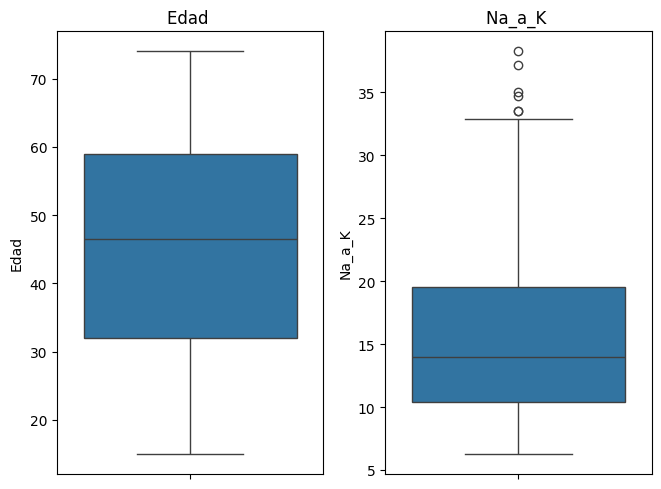

In [ ]:
# BOXPLOTS:
cols_num = ['Edad',	'Na_a_K']

plt.figure(figsize=(10,5))

for i, col in enumerate(cols_num):
    plt.subplot(1, 3, i+1)
    sns.boxplot( y=col, data=farmac1_train)
    plt.title(f"{col} ")

plt.tight_layout()
plt.show()

In [ ]:
#Eliminación outliers en 'Na_a_K'.
farmac1_train = outliers(farmac1_train,'Na_a_K')

Se eliminaron: 6 filas.


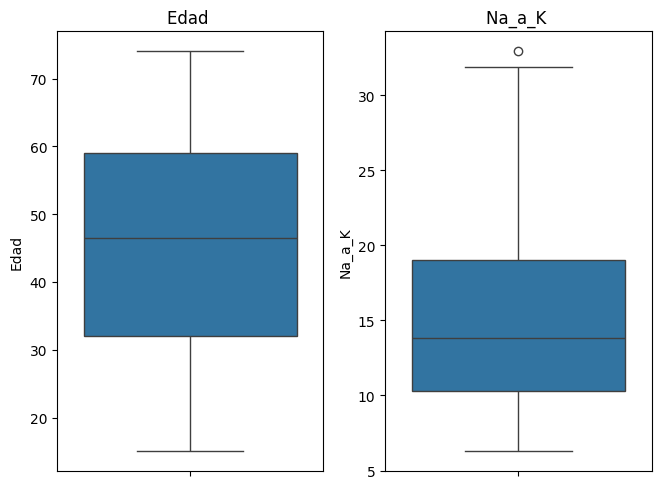

In [ ]:
# BOXPLOTS:
cols_num = ['Edad',	'Na_a_K']

plt.figure(figsize=(10,5))

for i, col in enumerate(cols_num):
    plt.subplot(1, 3, i+1)
    sns.boxplot( y=col, data=farmac1_train)
    plt.title(f"{col} ")

plt.tight_layout()
plt.show()

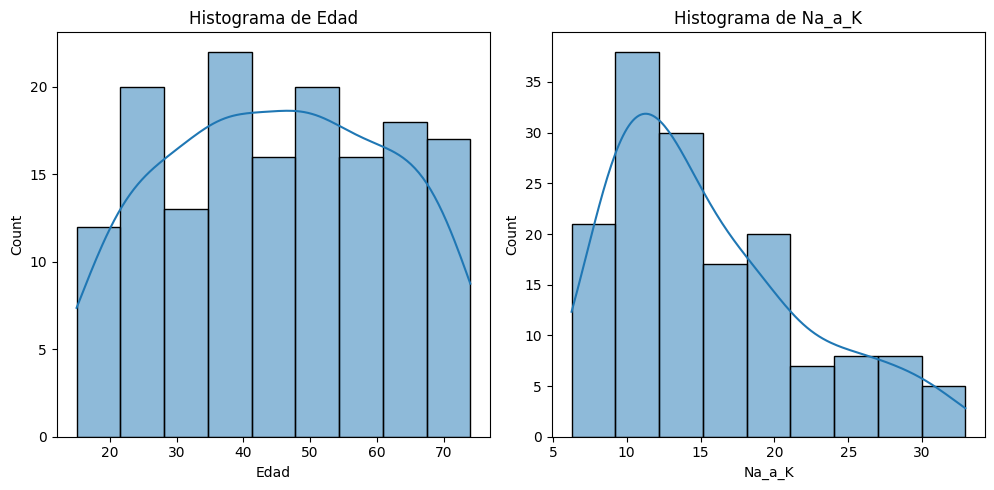

In [ ]:
# HISTOGRAMAS :
plt.figure(figsize=(15,5))

for i, col in enumerate(cols_num):
    plt.subplot(1, 3, i+1)
    sns.histplot(farmac1_train[col], kde=True)
    plt.title(f"Histograma de {col}")

plt.tight_layout()
plt.show()

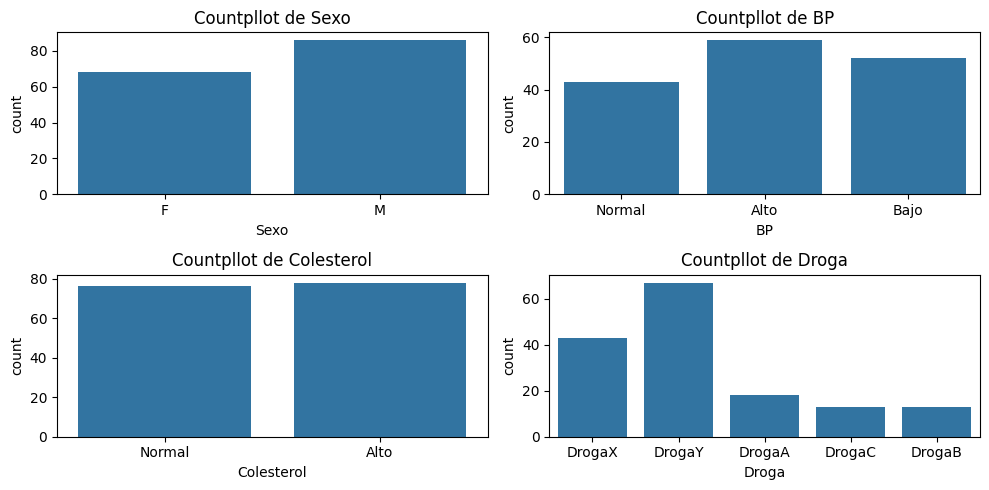

In [ ]:
# COUNTPLOT:
plt.figure(figsize=(10,5))

for i, col in enumerate(col_cat):
    plt.subplot(2, 2, i+1)
    sns.countplot(data=farmac1_train,x=col)
    plt.title(f"Countpllot de {col}")

plt.tight_layout()
plt.show()

Observamos que la variable Droga presenta un marcado desbalance de clases. La DrogaY es la categoría con notablemente mas observaciones, mientras que A, B y C cuentan con muchas menos.

La variable Colesterol muestra una distribución uniforme, mientras que en Sexo y BP se observan ligeras predominancias de las categorías 'Masculino' y 'Alto'.

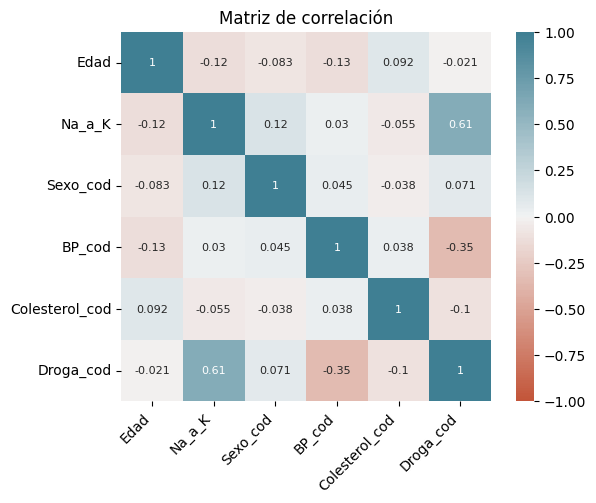

In [ ]:
# MATRIZ DE CORRELACION:
corr = farmac1_train.drop(columns=['Sexo','BP','Colesterol','Droga']).corr()

ax = sns.heatmap(corr,vmin=-1, vmax=1, center=0,cmap=sns.diverging_palette(20, 220, n=200),square=True,annot = True,annot_kws = {'size': 8})
ax.set_xticklabels(ax.get_xticklabels(),rotation=45,horizontalalignment='right')
plt.title('Matriz de correlación')
plt.show()

Identificamos que la variable Na_a_K presenta la mayor asociación con la variable Droga.

La BP muestra una correlación negativa moderada de -0.35. Variables como la Edad, el Sexo y el Colesterol tienen coeficientes cercanos a cero, lo que sugiere que no existe una relación lineal directa y fuerte entre estos atributos y la droga, dejando la capacidad predictiva principalmente a los factores químicos y de presión del paciente.

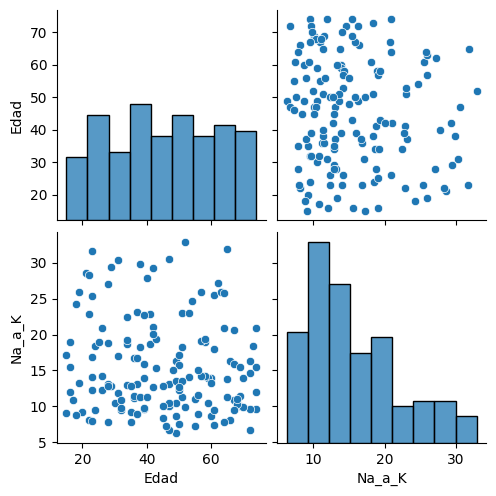

In [ ]:
# PAIRPLOT :
sns.pairplot(farmac1_train[['Edad','Na_a_K']])
plt.show()

### Conjunto 70/30

Se realizaron boxplots para cada variable numérica con el objetivo de identificar la presencia de valores atípicos.

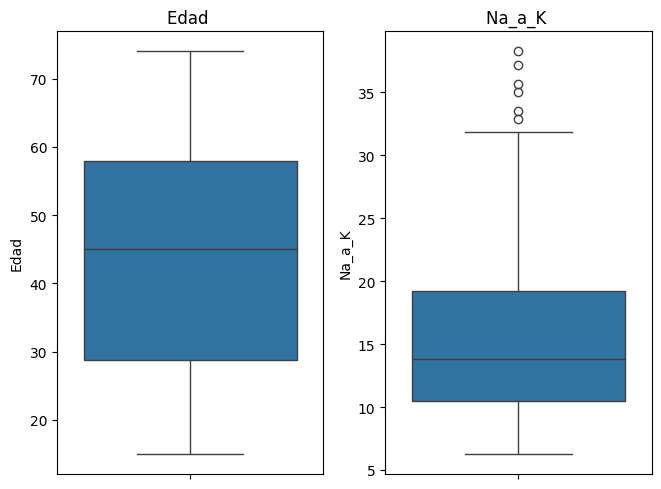

In [ ]:
# BOXPLOTS:
cols_num = ['Edad',	'Na_a_K']

plt.figure(figsize=(10,5))

for i, col in enumerate(cols_num):
    plt.subplot(1, 3, i+1)
    sns.boxplot( y=col, data=farmac2_train)
    plt.title(f"{col} ")

plt.tight_layout()
plt.show()

In [ ]:
#Eliminación outliers en 'Na_a_K'.
farmac2_train = outliers(farmac2_train,'Na_a_K')

Se eliminaron: 6 filas.


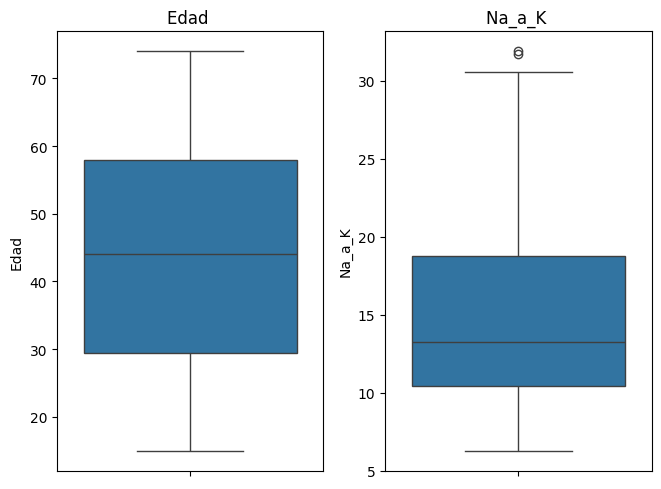

In [ ]:
# BOXPLOTS:
cols_num = ['Edad',	'Na_a_K']

plt.figure(figsize=(10,5))

for i, col in enumerate(cols_num):
    plt.subplot(1, 3, i+1)
    sns.boxplot( y=col, data=farmac2_train)
    plt.title(f"{col} ")

plt.tight_layout()
plt.show()

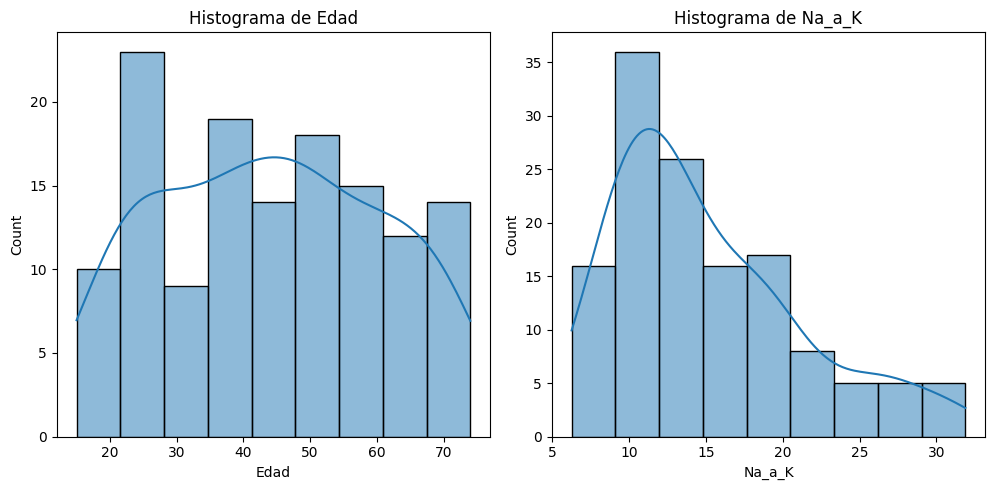

In [ ]:
# HISTOGRAMAS :
plt.figure(figsize=(15,5))

for i, col in enumerate(cols_num):
    plt.subplot(1, 3, i+1)
    sns.histplot(farmac2_train[col], kde=True)
    plt.title(f"Histograma de {col}")

plt.tight_layout()
plt.show()

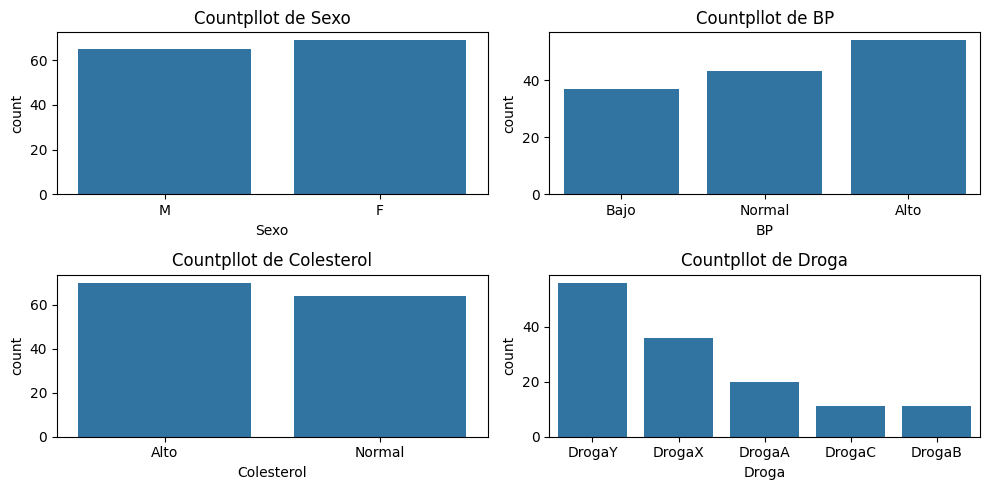

In [ ]:
# COUNTPLOT:
plt.figure(figsize=(10,5))

for i, col in enumerate(col_cat):
    plt.subplot(2, 2, i+1)
    sns.countplot(data=farmac2_train,x=col)
    plt.title(f"Countpllot de {col}")

plt.tight_layout()
plt.show()

Podemos observar que esta partición 70/30 presenta las mismas distribuciónes que la analizada antes.

##4) Árbol de dicisión para clasificación:

### Conjunto 80/20:

In [ ]:
#Separamos variables predictoras y objetivo:
X1_train = farmac1_train[['Edad','Sexo_cod','BP_cod','Colesterol_cod','Na_a_K']]
y1_train = farmac1_train['Droga_cod']

X1_test = farmac1_test[['Edad','Sexo_cod','BP_cod','Colesterol_cod','Na_a_K']]
y1_test = farmac1_test['Droga_cod']

In [ ]:
target_balance(pd.DataFrame({'class': y1_train}), 'class')

Balance de 'class':
class    Cantidad    Porcentaje
-------  ----------  ------------
4        67          44%
3        43          28%
0        18          12%
2        13          8%
1        13          8%


In [ ]:
target_balance(pd.DataFrame({'class': y1_test }), 'class')

Balance de 'class':
class    Cantidad    Porcentaje
-------  ----------  ------------
4        18          45%
3        11          28%
0        5           12%
1        3           8%
2        3           8%


#### a) Variando la profundidad del árbol ('max_deph'):

In [ ]:
profundidades = [2,3, 4, 6, 8]

resultados = []

for prof in profundidades:

    tree_clf = DecisionTreeClassifier(max_depth=prof,criterion='gini',min_samples_leaf=1,min_samples_split=2,random_state=63)

    # Entrenamiento
    tree_clf.fit(X1_train, y1_train)

    # Predicciones
    y_pred = tree_clf.predict(X1_test)

    # Metricas
    accuracy = accuracy_score(y1_test, y_pred)
    precision = precision_score(y1_test,y_pred,average='macro',zero_division=0)
    recall = recall_score(y1_test,y_pred,average='macro')

    resultados.append({'max_depth': prof,'Accuracy': accuracy,'Precision_macro': precision,'Recall_macro': recall})

resultados_farmac1 = pd.DataFrame(resultados)
display(resultados_farmac1)

,max_depth,Accuracy,Precision_macro,Recall_macro
0,2,0.850,0.482143,0.6
1,3,0.925,0.757143,0.8
2,4,1.000,1.000000,1.0
3,6,1.000,1.000000,1.0
4,8,1.000,1.000000,1.0


Al analizar la profundidad máxima del árbol, se observa que a partir de max_depth = 4 el modelo alcanza métricas perfectas, lo que sugiere un posible sobreajuste. Por este motivo seleccionamos max_depth = 3, ya que mantiene un Accuracy alto y una mejor capacidad de generalización sobre nuevos datos.

#### b) Variando el número mínimo de observaciones por hoja (min_samples_leaf) :

In [ ]:
hojas = [1, 3, 5, 10]

resultados = []

for h in hojas:

    tree_clf = DecisionTreeClassifier(max_depth=3,criterion='gini',min_samples_leaf=h,min_samples_split=2,random_state=63)
    # Entrenamiento
    tree_clf.fit(X1_train, y1_train)

    # Predicciones
    y_pred = tree_clf.predict(X1_test)

    # Metricas
    accuracy = accuracy_score(y1_test, y_pred)
    precision = precision_score(y1_test,y_pred,average='macro',zero_division=0)
    recall = recall_score(y1_test,y_pred,average='macro')

    resultados.append({'min_samples_leaf': h,'Accuracy': accuracy,'Precision_macro': precision,'Recall_macro': recall})

resultados_farmac1 = pd.DataFrame(resultados)
display(resultados_farmac1)

,min_samples_leaf,Accuracy,Precision_macro,Recall_macro
0,1,0.925,0.757143,0.8
1,3,0.925,0.757143,0.8
2,5,0.925,0.757143,0.8
3,10,0.925,0.757143,0.8


Observamos que las métricas permanecen constantes para todos los valores evaluados. Esto indica que el árbol ya presenta una estructura estable con la profundidad seleccionada y que modificar la cantidad mínima de observaciones por hoja no genera cambios significativos en el rendimiento del modelo.

#### c) Variando el número mínimo de observaciones para realizar una separación (min_samples_split):

In [ ]:
hojas = [2, 3, 5, 10]

resultados = []

for h in hojas:

    tree_clf = DecisionTreeClassifier(max_depth=3,criterion='gini',min_samples_leaf=1,min_samples_split=h,random_state=63)
    # Entrenamiento
    tree_clf.fit(X1_train, y1_train)

    # Predicciones
    y_pred = tree_clf.predict(X1_test)

    # Metricas
    accuracy = accuracy_score(y1_test, y_pred)
    precision = precision_score(y1_test,y_pred,average='macro',zero_division=0)
    recall = recall_score(y1_test,y_pred,average='macro')

    resultados.append({'min_samples_split': h,'Accuracy': accuracy,'Precision_macro': precision,'Recall_macro': recall})

resultados_farmac1 = pd.DataFrame(resultados)
display(resultados_farmac1)

,min_samples_split,Accuracy,Precision_macro,Recall_macro
0,2,0.925,0.757143,0.8
1,3,0.925,0.757143,0.8
2,5,0.925,0.757143,0.8
3,10,0.925,0.757143,0.8


Al analizar los hiperparámetros min_samples_leaf y min_samples_split, observamos que no se produjeron cambios en las métricas para los distintos valores evaluados. Esto indica que, una vez fijada la profundidad máxima del árbol, la estructura del modelo permanece estable frente a variaciones en estos parámetros. Por este motivo, seleccionamos los valores mínimos evaluados: min_samples_leaf = 1 y min_samples_split = 2.

#### d) Visualización árbol antes de la poda:

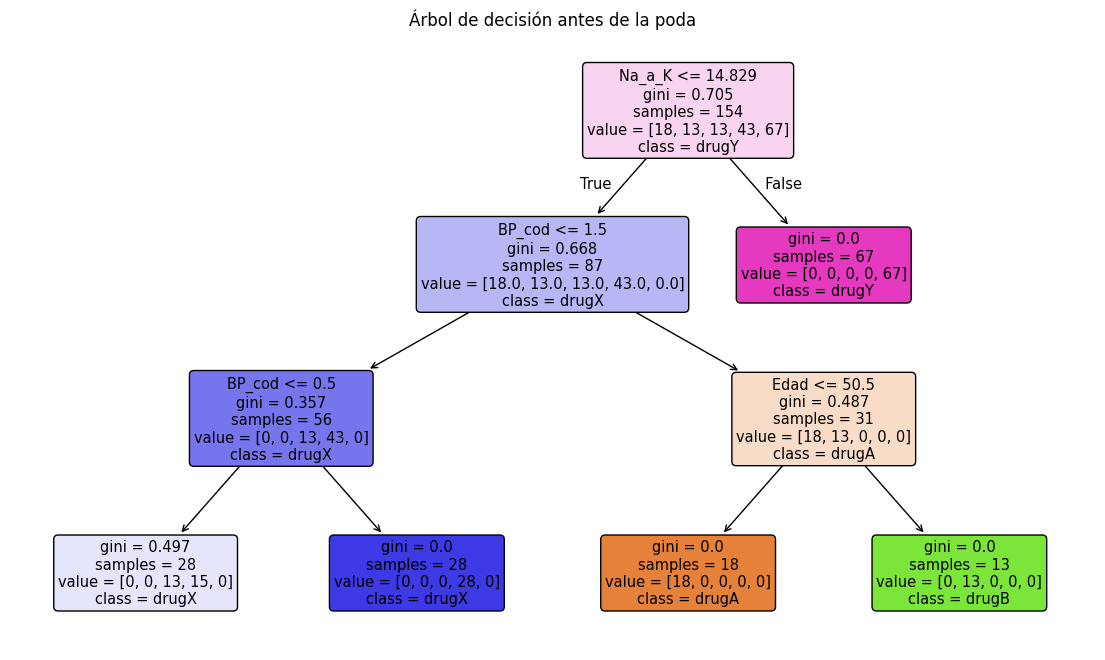

In [ ]:
# Mejor árbol
tree_8020 = DecisionTreeClassifier(max_depth=3,min_samples_leaf=1,min_samples_split=2,criterion='gini',random_state=63)

# Entrenamiento
tree_8020.fit(X1_train, y1_train)

# Predicciones
y_pred = tree_8020.predict(X1_test)

# Métricas
accuracy_8020 = accuracy_score(y1_test, y_pred)
precision_8020 = precision_score(y1_test,y_pred,average='macro',zero_division=0)
recall_8020 = recall_score(y1_test,y_pred,average='macro')

# Graficar
plt.figure(figsize=(14,8))

nombres_clases = ['drugA', 'drugB', 'drugC', 'drugX', 'drugY']
plot_tree(tree_clf,feature_names=X1_train.columns,class_names=nombres_clases,filled=True,rounded=True)
plt.title("Árbol de decisión antes de la poda")
plt.show()

#### e) Visualización árbol despues de la poda:

In [ ]:
alphas = [0, 0.001, 0.005, 0.01, 0.05]

resultados_poda = []

for alpha in alphas:

    tree_poda = DecisionTreeClassifier(max_depth=3,min_samples_leaf=1,min_samples_split=2,criterion='gini',ccp_alpha=alpha,random_state=63)

    tree_poda.fit(X1_train, y1_train)

    pred = tree_poda.predict(X1_test)

    accuracy = accuracy_score(y1_test, pred)
    precision = precision_score(y1_test,pred,average='macro',zero_division=0)
    recall = recall_score(y1_test,pred,average='macro')

    resultados_poda.append({'ccp_alpha': alpha,'Accuracy': accuracy,'Precision_macro': precision,'Recall_macro': recall})

resultados_poda = pd.DataFrame(resultados_poda)
display(resultados_poda.round(3))

,ccp_alpha,Accuracy,Precision_macro,Recall_macro
0,0.000,0.925,0.757,0.8
1,0.001,0.925,0.757,0.8
2,0.005,0.925,0.757,0.8
3,0.010,0.925,0.757,0.8
4,0.050,0.925,0.757,0.8


Observamos que las métricas permanecieron constantes para todos los valores de ccp_alpha evaluados. Esto indica que la poda no produjo cambios en la estructura ni en el rendimiento del árbol, por lo que concluimos que no fue necesario aplicar poda al modelo.

### Conjunto 70/30:

In [ ]:
#Separamos variables predictoras y objetivo:
X2_train = farmac2_train[['Edad','Sexo_cod','BP_cod','Colesterol_cod','Na_a_K']]
y2_train = farmac2_train['Droga_cod']

X2_test = farmac2_test[['Edad','Sexo_cod','BP_cod','Colesterol_cod','Na_a_K']]
y2_test = farmac2_test['Droga_cod']

In [ ]:
target_balance(pd.DataFrame({'class': y2_train}), 'class')

Balance de 'class':
class    Cantidad    Porcentaje
-------  ----------  ------------
4        56          42%
3        36          27%
0        20          15%
2        11          8%
1        11          8%


In [ ]:
target_balance(pd.DataFrame({'class': y2_test }), 'class')

Balance de 'class':
class    Cantidad    Porcentaje
-------  ----------  ------------
4        29          48%
3        18          30%
2        5           8%
1        5           8%
0        3           5%


#### a) Variando la profundidad del árbol ('max_deph'):

In [ ]:
profundidades = [2,3, 4, 6, 8]

resultados = []

for prof in profundidades:

    tree_clf = DecisionTreeClassifier(max_depth=prof,criterion='gini',min_samples_leaf=1,min_samples_split=2,random_state=63)

    # Entrenamiento
    tree_clf.fit(X2_train, y2_train)

    # Predicciones
    y_pred = tree_clf.predict(X2_test)

    # Metricas
    accuracy = accuracy_score(y2_test, y_pred)
    precision = precision_score(y2_test,y_pred,average='macro',zero_division=0)
    recall = recall_score(y2_test,y_pred,average='macro')

    resultados.append({'max_depth': prof,'Accuracy': accuracy,'Precision_macro': precision,'Recall_macro': recall})

resultados_farmac1 = pd.DataFrame(resultados)
display(resultados_farmac1)

,max_depth,Accuracy,Precision_macro,Recall_macro
0,2,0.816667,0.422879,0.588889
1,3,0.850000,0.826667,0.871111
2,4,0.966667,0.943333,0.948889
3,6,0.966667,0.943333,0.948889
4,8,0.966667,0.943333,0.948889


Observamos que a partir de max_depth = 4 las métricas alcanzan valores muy elevados y permanecen constantes para profundidades mayores, lo que sugiere un posible sobreajuste. Seleccionamos max_depth = 3, ya que presenta un buen equilibrio entre desempeño y capacidad de generalización.

#### b) Variando el número mínimo de observaciones por hoja (min_samples_leaf) :

In [ ]:
hojas = [1, 3, 5, 10]

resultados = []

for h in hojas:

    tree_clf = DecisionTreeClassifier(max_depth=3,criterion='gini',min_samples_leaf=h,min_samples_split=2,random_state=63)
    # Entrenamiento
    tree_clf.fit(X2_train, y2_train)

    # Predicciones
    y_pred = tree_clf.predict(X2_test)

    # Metricas
    accuracy = accuracy_score(y2_test, y_pred)
    precision = precision_score(y2_test,y_pred,average='macro',zero_division=0)
    recall = recall_score(y2_test,y_pred,average='macro')

    resultados.append({'min_samples_leaf': h,'Accuracy': accuracy,'Precision_macro': precision,'Recall_macro': recall})

resultados_farmac1 = pd.DataFrame(resultados)
display(resultados_farmac1)

,min_samples_leaf,Accuracy,Precision_macro,Recall_macro
0,1,0.85,0.826667,0.871111
1,3,0.85,0.826667,0.871111
2,5,0.85,0.826667,0.871111
3,10,0.85,0.826667,0.871111


#### c) Variando el número mínimo de observaciones para realizar una separación (min_samples_split):

In [ ]:
hojas = [2, 3, 5, 10]

resultados = []

for h in hojas:

    tree_clf = DecisionTreeClassifier(max_depth=3,criterion='gini',min_samples_leaf=1,min_samples_split=h,random_state=63)
    # Entrenamiento
    tree_clf.fit(X2_train, y2_train)

    # Predicciones
    y_pred = tree_clf.predict(X2_test)

    # Metricas
    accuracy = accuracy_score(y2_test, y_pred)
    precision = precision_score(y2_test,y_pred,average='macro',zero_division=0)
    recall = recall_score(y2_test,y_pred,average='macro')

    resultados.append({'min_samples_split': h,'Accuracy': accuracy,'Precision_macro': precision,'Recall_macro': recall})

resultados_farmac1 = pd.DataFrame(resultados)
display(resultados_farmac1)

,min_samples_split,Accuracy,Precision_macro,Recall_macro
0,2,0.85,0.826667,0.871111
1,3,0.85,0.826667,0.871111
2,5,0.85,0.826667,0.871111
3,10,0.85,0.826667,0.871111


Al analizar los hiperparámetros min_samples_leaf y min_samples_split, no se observaron cambios en las métricas para los distintos valores. Esto indica que, una vez fijada la profundidad máxima del árbol, la estructura del modelo permanece estable frente a variaciones en estos parámetros. Seleccionamos los valores mínimos evaluados: min_samples_leaf = 1 y min_samples_split = 2.

#### d) Visualización árbol antes de la poda:

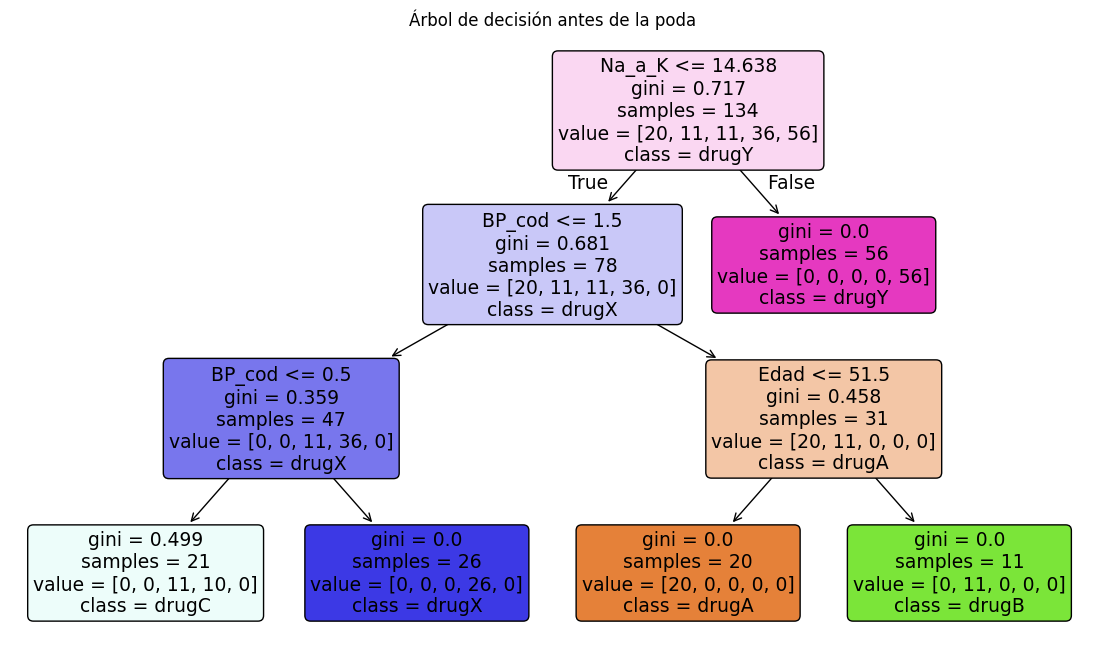

In [ ]:
# Mejor árbol
tree_7030 = DecisionTreeClassifier(max_depth=3,min_samples_leaf=1,min_samples_split=2,criterion='gini',random_state=63)

# Entrenamiento
tree_7030.fit(X2_train, y2_train)

# Predicciones
y_pred = tree_7030.predict(X2_test)

# Métricas
accuracy_7030 = accuracy_score(y2_test, y_pred)
precision_7030 = precision_score(y2_test,y_pred,average='macro',zero_division=0)
recall_7030 = recall_score(y2_test,y_pred,average='macro')

# Graficar
plt.figure(figsize=(14,8))

nombres_clases = ['drugA', 'drugB', 'drugC', 'drugX', 'drugY']
plot_tree(tree_clf,feature_names=X2_train.columns,class_names=nombres_clases,filled=True,rounded=True)
plt.title("Árbol de decisión antes de la poda")
plt.show()

#### e) Visualización árbol despues de la poda:

In [ ]:
alphas = [0, 0.001, 0.005, 0.01, 0.05]

resultados_poda = []

for alpha in alphas:

    tree_poda = DecisionTreeClassifier(max_depth=3,min_samples_leaf=1,min_samples_split=2,criterion='gini',ccp_alpha=alpha,random_state=63)

    tree_poda.fit(X2_train, y2_train)

    pred = tree_poda.predict(X2_test)

    accuracy = accuracy_score(y2_test, pred)
    precision = precision_score(y2_test,pred,average='macro',zero_division=0)
    recall = recall_score(y2_test,pred,average='macro')

    resultados_poda.append({'ccp_alpha': alpha,'Accuracy': accuracy,'Precision_macro': precision,'Recall_macro': recall})

resultados_poda = pd.DataFrame(resultados_poda)
display(resultados_poda.round(3))

,ccp_alpha,Accuracy,Precision_macro,Recall_macro
0,0.000,0.850,0.827,0.871
1,0.001,0.850,0.827,0.871
2,0.005,0.850,0.827,0.871
3,0.010,0.850,0.827,0.871
4,0.050,0.883,0.698,0.749


Observamos que las métricas se mantuvieron estables para valores bajos de ccp_alpha. Sin embargo, al aumentar ccp_alpha a 0.05, el Accuracy mejoró levemente pero disminuyeron considerablemente la Precision y el Recall macro. Esto indica una pérdida en la capacidad de clasificación general, por lo que concluimos que no fue conveniente aplicar poda al modelo.

### Comparación:

In [ ]:
resultados = pd.DataFrame({
    'Modelo': ['Árbol 80/20', 'Árbol 70/30'],
    'Accuracy': [accuracy_8020, accuracy_7030],
    'Precision Macro': [precision_8020, precision_7030],
    'Recall Macro': [recall_8020, recall_7030]})

display(resultados.round(3))

,Modelo,Accuracy,Precision Macro,Recall Macro
0,Árbol 80/20,0.925,0.757,0.800
1,Árbol 70/30,0.850,0.827,0.871


Observamos que el modelo con partición 80/20 obtuvo mayor Accuracy, mientras que la partición 70/30 presentó mejores valores de Precision y Recall macro. En general, ambos modelos mostraron un buen desempeño y una adecuada capacidad de clasificación.

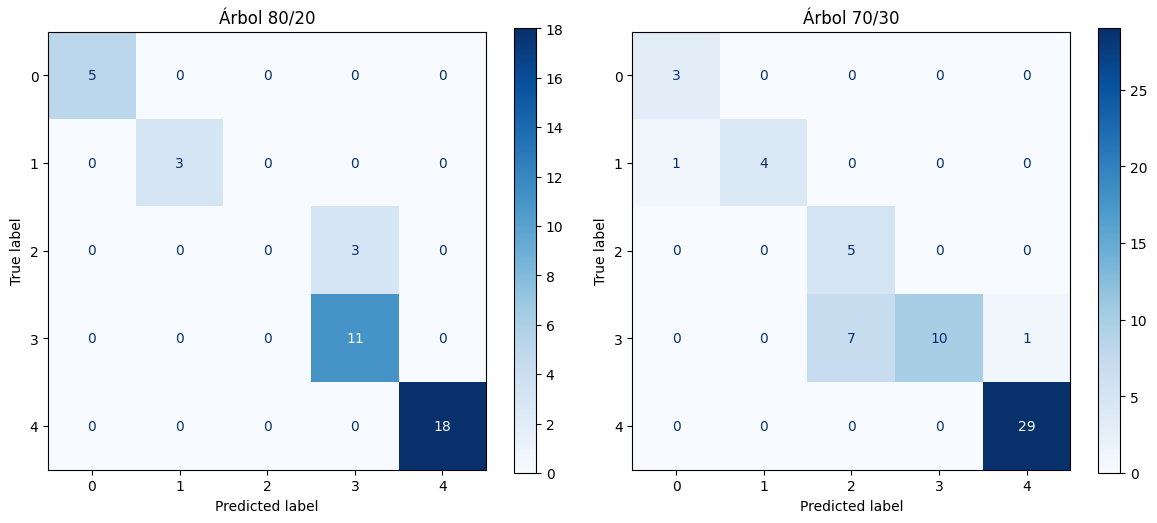

In [ ]:
# Predicciones
pred_8020 = tree_8020.predict(X1_test)
pred_7030 = tree_7030.predict(X2_test)

# Subplots
fig, axes = plt.subplots(1, 2, figsize=(12,5))

# Matriz 80/20
ConfusionMatrixDisplay.from_predictions(y1_test,pred_8020,cmap=plt.cm.Blues,ax=axes[0])
axes[0].set_title("Árbol 80/20")

# Matriz 70/30
ConfusionMatrixDisplay.from_predictions(y2_test,pred_7030,cmap=plt.cm.Blues,ax=axes[1])
axes[1].set_title("Árbol 70/30")

plt.tight_layout()
plt.show()

En esta sección implementamos Árboles de Decisión para clasificar el tipo de droga farmacéutica utilizando dos particiones distintas del dataset: 80/20 y 70/30 para entrenamiento y prueba. Esto nos permitió observar cómo se comporta el modelo frente a diferentes cantidades de datos de entrenamiento y evaluar su capacidad de generalización.

Para mejorar el rendimiento del modelo, analizamos distintos hiperparámetros como la profundidad máxima del árbol (max_depth), la cantidad mínima de observaciones por hoja (min_samples_leaf) y la cantidad mínima de observaciones necesarias para realizar una separación (min_samples_split).

Observamos que, al aumentar demasiado la profundidad del árbol, las métricas alcanzaban valores extremadamente altos, lo que podría indicar un posible sobreajuste. Por este motivo, seleccionamos una profundidad máxima de 3 niveles, ya que permitió obtener buenos resultados manteniendo una estructura más simple y generalizable.

También observamos que modificar los parámetros min_samples_leaf y min_samples_split no generó cambios significativos en las métricas obtenidas. Esto indica que, una vez definida la profundidad del árbol, la estructura del modelo se mantuvo estable.

Con respecto a la poda utilizando ccp_alpha, no encontramos mejoras importantes en el rendimiento del modelo, por lo que concluimos que no era necesario aplicar poda adicional.

En general, obtuvimos buenos resultados de Accuracy, Precision y Recall tanto en la partición 80/20 como en la 70/30, lo que demuestra que el modelo logró clasificar correctamente la mayoría de las observaciones.

##5) Bayes Ingenuo:

### Gaussian Naïve Bayes (GaussianNB)

#### Conjunto 80/20:

In [ ]:
#Separamos variables predictoras y objetivo:
X1_train = farmac1_train[['Edad','Sexo_cod','BP_cod','Colesterol_cod','Na_a_K']]
y1_train = farmac1_train['Droga_cod']

X1_test = farmac1_test[['Edad','Sexo_cod','BP_cod','Colesterol_cod','Na_a_K']]
y1_test = farmac1_test['Droga_cod']

In [ ]:
# Definición y Entrenamiento del Modelo
clf_GNB = GaussianNB()
clf_GNB.fit(X1_train, y1_train)

GaussianNB()

In [ ]:
# Testeo
pred_GNB_1 = clf_GNB.predict(X1_test)

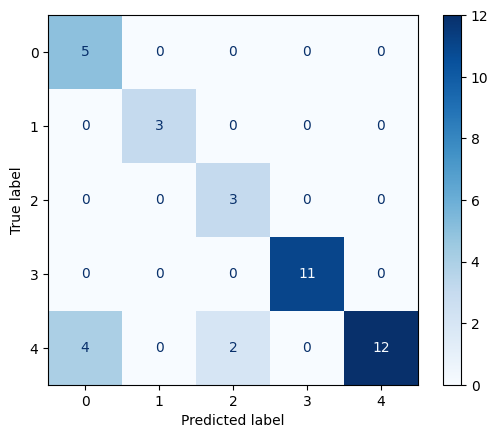

In [ ]:
ConfusionMatrixDisplay.from_predictions(y1_test, pred_GNB_1, cmap=plt.cm.Blues)

#### Conjunto 70/30:

In [ ]:
#Separamos variables predictoras y objetivo:
X2_train = farmac2_train[['Edad','Sexo_cod','BP_cod','Colesterol_cod','Na_a_K']]
y2_train = farmac2_train['Droga_cod']

X2_test = farmac1_test[['Edad','Sexo_cod','BP_cod','Colesterol_cod','Na_a_K']]
y2_test = farmac1_test['Droga_cod']

In [ ]:
# Definición y Entrenamiento del Modelo
clf_GNB = GaussianNB()
clf_GNB.fit(X2_train, y2_train)

GaussianNB()

In [ ]:
# Testeo
pred_GNB_2 = clf_GNB.predict(X2_test)

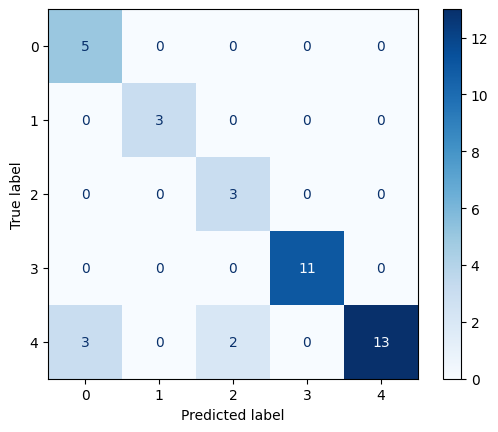

In [ ]:
ConfusionMatrixDisplay.from_predictions(y2_test, pred_GNB_2, cmap=plt.cm.Blues)

### Multinomial Naïve Bayes (MultinomialNB)

#### Conjunto 80/20:

Discretización de las columnas 'Edad' y 'Na_a_k' utilizando 3 y 5 intervalos.

In [ ]:
columnas = ['Edad', 'Na_a_K']

# 3 intervalos
farmac1_train_3, farmac1_test_3 = discretizar(farmac1_train, farmac1_test, columnas, 3)
# 5 intervalos
farmac1_train_5, farmac1_test_5 = discretizar(farmac1_train, farmac1_test, columnas, 5)

##### Utilizando 3 intervalos:

In [ ]:
# Selección de variables.
cols_X = ['Edad_disc', 'Sexo_cod', 'BP_cod', 'Colesterol_cod', 'Na_a_K_disc']

X1_train_3 = farmac1_train_3[cols_X]
y1_train_3 = farmac1_train_3['Droga_cod']

X1_test_3 = farmac1_test_3[cols_X]
y1_test_3 = farmac1_test_3['Droga_cod']

In [ ]:
#  Definición y Entrenamiento del Modelo
clf_MNB = MultinomialNB()
clf_MNB.fit(X1_train_3, y1_train_3)

MultinomialNB()

In [ ]:
# Testeo
pred1_MNB_3= clf_MNB.predict(X1_test_3)

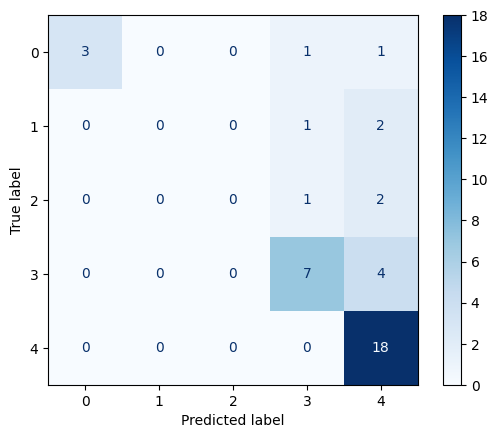

In [ ]:
ConfusionMatrixDisplay.from_predictions(y1_test_3, pred1_MNB_3, cmap=plt.cm.Blues)

##### Utilizando 5 intervalos:

In [ ]:
# Selección de variables.
cols_X = ['Edad_disc', 'Sexo_cod', 'BP_cod', 'Colesterol_cod', 'Na_a_K_disc']

X1_train_5 = farmac1_train_5[cols_X]
y1_train_5 = farmac1_train_5['Droga_cod']

X1_test_5 = farmac1_test_5[cols_X]
y1_test_5 = farmac1_test_5['Droga_cod']

In [ ]:
#  Definición y Entrenamiento del Modelo
clf_MNB = MultinomialNB()
clf_MNB.fit(X1_train_5, y1_train_5)

MultinomialNB()

In [ ]:
# Testeo
pred1_MNB_5 = clf_MNB.predict(X1_test_5)

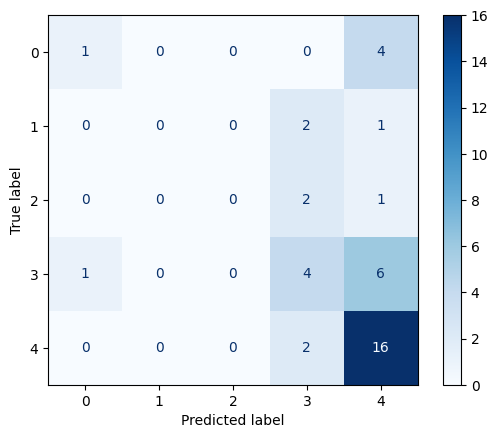

In [ ]:
ConfusionMatrixDisplay.from_predictions(y1_test_5, pred1_MNB_5, cmap=plt.cm.Blues)

#### Conjunto 70/30:

Discretización de las columnas 'Edad' y 'Na_a_k' utilizando 3 y 5 intervalos.

In [ ]:
columnas = ['Edad', 'Na_a_K']

# 3 intervalos
farmac2_train_3, farmac2_test_3 = discretizar(farmac2_train, farmac2_test, columnas, 3)
# 5 intervalos
farmac2_train_5, farmac2_test_5 = discretizar(farmac2_train, farmac2_test, columnas, 5)

##### Utilizando 3 intervalos:

In [ ]:
# Selección de variables.
cols_X = ['Edad_disc', 'Sexo_cod', 'BP_cod', 'Colesterol_cod', 'Na_a_K_disc']

X2_train_3 = farmac2_train_3[cols_X]
y2_train_3 = farmac2_train_3['Droga_cod']

X2_test_3 = farmac2_test_3[cols_X]
y2_test_3 = farmac2_test_3['Droga_cod']

In [ ]:
#  Definición y Entrenamiento del Modelo
clf_MNB = MultinomialNB()
clf_MNB.fit(X2_train_3, y2_train_3)

MultinomialNB()

In [ ]:
# Testeo
pred2_MNB_3= clf_MNB.predict(X2_test_3)

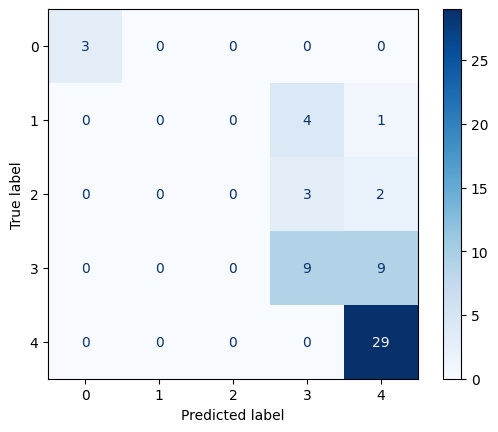

In [ ]:
ConfusionMatrixDisplay.from_predictions(y2_test_3, pred2_MNB_3, cmap=plt.cm.Blues)

##### Utilizando 5 intervalos:

In [ ]:
# Selección de variables.
cols_X = ['Edad_disc', 'Sexo_cod', 'BP_cod', 'Colesterol_cod', 'Na_a_K_disc']

X2_train_5 = farmac2_train_5[cols_X]
y2_train_5 = farmac2_train_5['Droga_cod']

X2_test_5 = farmac2_test_5[cols_X]
y2_test_5 = farmac2_test_5['Droga_cod']

In [ ]:
#  Definición y Entrenamiento del Modelo
clf_MNB = MultinomialNB()
clf_MNB.fit(X2_train_5, y2_train_5)

MultinomialNB()

In [ ]:
# Testeo
pred2_MNB_5= clf_MNB.predict(X2_test_5)

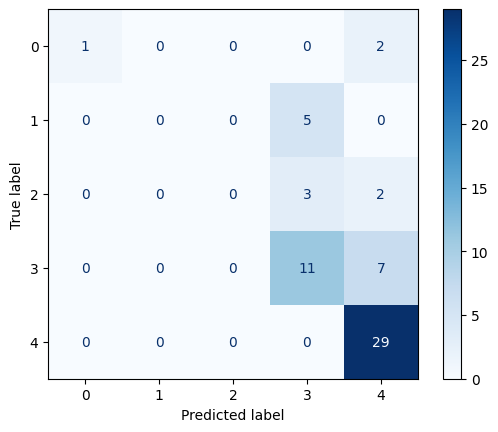

In [ ]:
ConfusionMatrixDisplay.from_predictions(y2_test_5, pred2_MNB_5, cmap=plt.cm.Blues)

### CONCLUSIÓN:

In [ ]:
# GNB 80/20
precision_GNB_8020 = precision_score(y1_test, pred_GNB_1, average='macro')
accuracy_GNB_8020 = accuracy_score(y1_test, pred_GNB_1)
recall_GNB_8020 = recall_score(y1_test, pred_GNB_1, average='macro')

# GNB 70/30
precision_GNB_7030 = precision_score(y2_test, pred_GNB_2, average='macro')
accuracy_GNB_7030 = accuracy_score(y2_test, pred_GNB_2)
recall_GNB_7030 = recall_score(y2_test, pred_GNB_2, average='macro')

# MNB 80/20 - 3 bins
precision_MNB_80203 = precision_score(y1_test_3, pred1_MNB_3, average='macro')
accuracy_MNB_80203 = accuracy_score(y1_test_3, pred1_MNB_3)
recall_MNB_80203 = recall_score(y1_test_3, pred1_MNB_3, average='macro')

# MNB 80/20 - 5 bins
precision_MNB_80205 = precision_score(y1_test_5, pred1_MNB_5, average='macro')
accuracy_MNB_80205 = accuracy_score(y1_test_5, pred1_MNB_5)
recall_MNB_80205 = recall_score(y1_test_5, pred1_MNB_5, average='macro')

# MNB 70/30 - 3 bins
precision_MNB_70303 = precision_score(y2_test_3, pred2_MNB_3, average='macro')
accuracy_MNB_70303 = accuracy_score(y2_test_3, pred2_MNB_3)
recall_MNB_70303 = recall_score(y2_test_3, pred2_MNB_3, average='macro')

# MNB 70/30 - 5 bins
precision_MNB_70305 = precision_score(y2_test_5, pred2_MNB_5, average='macro')
accuracy_MNB_70305 = accuracy_score(y2_test_5, pred2_MNB_5)
recall_MNB_70305 = recall_score(y2_test_5, pred2_MNB_5, average='macro')

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/m

In [ ]:
resultados = pd.DataFrame({
    'Modelo': ['GaussianNB 80/20','GaussianNB 70/30','MultinomialNB 80/20 - 3 bins','MultinomialNB 80/20 - 5 bins','MultinomialNB 70/30 - 3 bins','MultinomialNB 70/30 - 5 bins'],
    'Accuracy': [accuracy_GNB_8020,accuracy_GNB_7030,accuracy_MNB_80203,accuracy_MNB_80205,accuracy_MNB_70303,accuracy_MNB_70305],
    'Precision Macro': [precision_GNB_8020,precision_GNB_7030,precision_MNB_80203,precision_MNB_80205,precision_MNB_70303,precision_MNB_70305],
    'Recall Macro': [recall_GNB_8020,recall_GNB_7030,recall_MNB_80203,recall_MNB_80205,recall_MNB_70303,recall_MNB_70305]
    })

display(resultados)

,Modelo,Accuracy,Precision Macro,Recall Macro
0,GaussianNB 80/20,0.850000,0.831111,0.933333
1,GaussianNB 70/30,0.875000,0.845000,0.944444
2,MultinomialNB 80/20 - 3 bins,0.700000,0.473333,0.447273
3,MultinomialNB 80/20 - 5 bins,0.525000,0.294286,0.290505
4,MultinomialNB 70/30 - 3 bins,0.683333,0.453963,0.500000
5,MultinomialNB 70/30 - 5 bins,0.683333,0.460789,0.388889


A partir de las matrices de confusión obtenidas, se observa que el modelo GaussianNB presenta el mejor desempeño general en ambos conjuntos de prueba. La mayoría de las observaciones fueron clasificadas correctamente. Las clases 0, 1, 2 y 3 fueron identificadas casi sin errores, mientras que las principales confusiones se fuero con la clase 4. Sin embargo, los errores fueron pocos, lo que explica los buenos resultados obtenidos en las metricas.

Los modelos MultinomialNB mostraron un rendimiento menor. Al discretizar las variables continuas, se pierde parte de la información original. En sus matrices de confusión se puede observar una mayor dispersión de las predicciones y una tendencia del modelo a concentrar las clasificaciones en las categorías 3 y 4

Al comparar las discretizaciones realizadas con 3 y 5 intervalos, se observó que la discretización en 3 bins produjo mejores resultados generales. Esto sugiere que una discretización más simple permitió conservar patrones más representativos de los datos, mientras que aumentar la cantidad de intervalos generó categorías demasiado específicas y con menor cantidad de observaciones, dificultando la estimación de probabilidades.

En conclusión, los resultados indican que GaussianNB fue el modelo más adecuado para este problema, ya que logró aprovechar de manera más eficiente la información de las variables continuas sin necesidad de discretización. Por su parte, MultinomialNB presentó un desempeño aceptable únicamente con discretizaciones más simples.

##6) k-NN:

### Conjunto 80/20:

Selección de k:

In [ ]:
# Escalado
scaler = StandardScaler()

X1_train_scaled = scaler.fit_transform(X1_train)
X1_test_scaled = scaler.transform(X1_test)

# Hiperparámetros
vecinos = [1,3,5,7,9]
metricas = ['euclidean', 'manhattan']

resultados = []

for k in vecinos:

    for metrica in metricas:
        knn = KNeighborsClassifier(n_neighbors=k,metric=metrica)

        # Entrenamiento
        knn.fit(X1_train_scaled, y1_train)

        # Predicción
        pred = knn.predict(X1_test_scaled)

        # Métricas
        accuracy = accuracy_score(y1_test, pred)
        precision = precision_score(y1_test,pred,average='macro',zero_division=0)
        recall = recall_score(y1_test,pred,average='macro')

        resultados.append({'k': k,'metric': metrica,'Accuracy': accuracy,'Precision_macro': precision,'Recall_macro': recall})

resultados_knn_8020 = pd.DataFrame(resultados)
display(resultados_knn_8020.round(3))

,k,metric,Accuracy,Precision_macro,Recall_macro
0,1,euclidean,0.850,0.813,0.897
1,1,manhattan,0.850,0.813,0.897
2,3,euclidean,0.900,0.886,0.956
3,3,manhattan,0.850,0.847,0.926
4,5,euclidean,0.850,0.856,0.926
5,5,manhattan,0.850,0.850,0.878
6,7,euclidean,0.775,0.793,0.746
7,7,manhattan,0.750,0.746,0.735
8,9,euclidean,0.750,0.768,0.728
9,9,manhattan,0.825,0.839,0.831


### Conjunto 70/30:

Selección de k:

In [ ]:
# Escalado
scaler = StandardScaler()

X2_train_scaled = scaler.fit_transform(X2_train)
X2_test_scaled = scaler.transform(X2_test)

# Hiperparámetros
vecinos = [1,3,5,7,9]
metricas = ['euclidean', 'manhattan']

resultados = []

for k in vecinos:

    for metrica in metricas:
        knn = KNeighborsClassifier(n_neighbors=k,metric=metrica)

        # Entrenamiento
        knn.fit(X2_train_scaled, y2_train)

        # Predicción
        pred = knn.predict(X2_test_scaled)

        # Métricas
        accuracy = accuracy_score(y2_test, pred)
        precision = precision_score(y2_test,pred,average='macro',zero_division=0)
        recall = recall_score(y2_test,pred,average='macro')

        resultados.append({'k': k,'metric': metrica,'Accuracy': accuracy,'Precision_macro': precision,'Recall_macro': recall})

resultados_knn_7030 = pd.DataFrame(resultados)
display(resultados_knn_7030.round(3))

,k,metric,Accuracy,Precision_macro,Recall_macro
0,1,euclidean,1.000,1.000,1.000
1,1,manhattan,1.000,1.000,1.000
2,3,euclidean,0.925,0.919,0.967
3,3,manhattan,0.950,0.933,0.978
4,5,euclidean,0.925,0.900,0.967
5,5,manhattan,0.875,0.820,0.889
6,7,euclidean,0.900,0.847,0.927
7,7,manhattan,0.925,0.932,0.938
8,9,euclidean,0.925,0.899,0.931
9,9,manhattan,0.875,0.849,0.908


### Matriz de confusión:

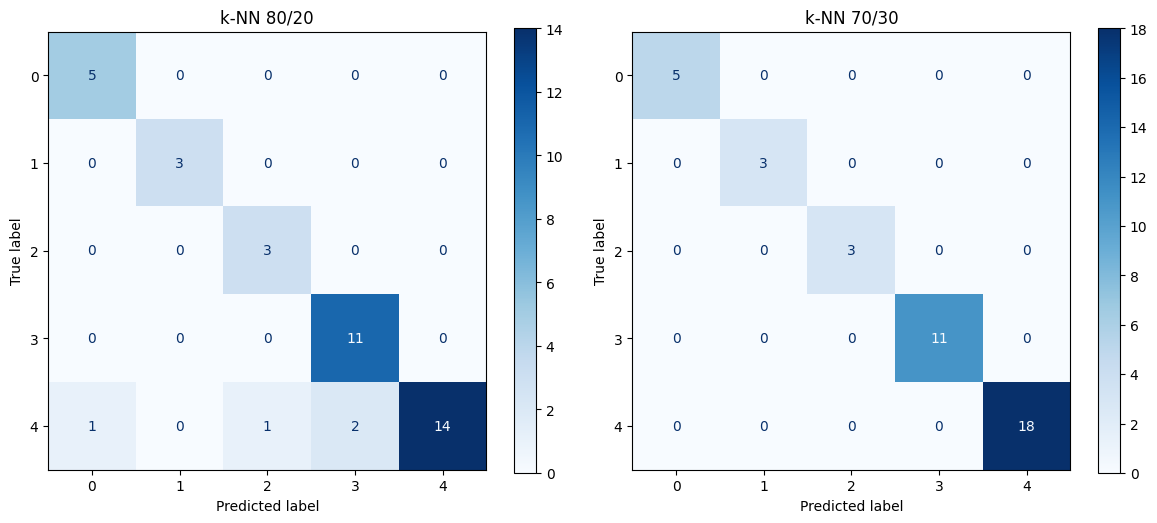

In [ ]:
# Modelo 80/20
knn_8020 = KNeighborsClassifier(n_neighbors=3,metric='euclidean')
knn_8020.fit(X1_train_scaled, y1_train)
pred_8020 = knn_8020.predict(X1_test_scaled)


# Modelo 70/30
knn_7030 = KNeighborsClassifier(n_neighbors=1,metric='manhattan')
knn_7030.fit(X2_train_scaled, y2_train)
pred_7030 = knn_7030.predict(X2_test_scaled)

# Subplots
fig, axes = plt.subplots(1, 2, figsize=(12,5))

# Matriz 80/20
ConfusionMatrixDisplay.from_predictions(y1_test,pred_8020,cmap=plt.cm.Blues,ax=axes[0])
axes[0].set_title("k-NN 80/20")

# Matriz 70/30
ConfusionMatrixDisplay.from_predictions(y2_test,pred_7030,cmap=plt.cm.Blues,ax=axes[1])
axes[1].set_title("k-NN 70/30")

plt.tight_layout()
plt.show()

Las matrices de confusión muestran un buen desempeño del modelo k-NN en ambas particiones, observamos una predominancia en los valores de la diagonarl principal, lo que indica una alta cantidad de clasificaciones correctas.

En la partición 80/20, utilizando k = 3 y distancia euclidiana, el modelo obtuvo un Accuracy = 0.90, Precision = 0.886 y Recall = 0.956. La matriz de confusión muestra que la mayoría de las clases fueron clasificadas correctamente; pero se observan algunos errores en la clase 4. Esto indica una leve dificultad para diferenciar esa categoría.

Por otro lado, la partición 70/30, con k = 1 y distancia Manhattan, alcanzó métricas perfectas (Accuracy = Precision = Recall = 1.00). La matriz de confusión presenta únicamente valores en la diagonal principal, indicando que todas las observaciones fueron clasificadas correctamente y no se registraron errores.

Comparando, el esquema 70/30 mostró mejor desempeño. El uso de k = 1 implica una mayor sensibilidad al ruido y posibles problemas de sobreajuste, por lo que el modelo 80/20 con k = 3 podría considerarse una alternativa más robusta a pesar de presentar una precisión ligeramente menor.

##7) Comparación de modelos:

In [ ]:
comparacion_modelos = pd.DataFrame({

    'Modelo': [
        'Árbol de Decisión 80/20',
        'Árbol de Decisión 70/30',
        'GaussianNB 80/20',
        'GaussianNB 70/30',
        'k-NN 80/20',
        'k-NN 70/30'
    ],

    'Accuracy': [
        accuracy_8020,
        accuracy_7030,
        accuracy_GNB_8020,
        accuracy_GNB_7030,
        0.900,
        1.000
    ],

    'Precision Macro': [
        precision_8020,
        precision_7030,
        precision_GNB_8020,
        precision_GNB_7030,
        0.886,
        1.000
    ],

    'Recall Macro': [
        recall_8020,
        recall_7030,
        recall_GNB_8020,
        recall_GNB_7030,
        0.956,
        1.000
    ]

})

display(comparacion_modelos.round(3))

,Modelo,Accuracy,Precision Macro,Recall Macro
0,Árbol de Decisión 80/20,0.925,0.757,0.800
1,Árbol de Decisión 70/30,0.850,0.827,0.871
2,GaussianNB 80/20,0.850,0.831,0.933
3,GaussianNB 70/30,0.875,0.845,0.944
4,k-NN 80/20,0.900,0.886,0.956
5,k-NN 70/30,1.000,1.000,1.000


Realizamos una comparación entre los tres modelos de clasificación implementados: Árbol de Decisión, Naive Bayes y k-NN, utilizando las particiones 80/20 y 70/30 del conjunto de datos.

En el caso del Árbol de Decisión, observamos buenos resultados en ambos conjuntos de prueba. Con la partición 80/20 se obtuvo un Accuracy de 0.925, mientras que con 70/30 el Accuracy fue de 0.850. Además, una de las ventajas más importantes de este modelo fue su interpretabilidad, ya que permite visualizar fácilmente las reglas utilizadas para clasificar cada tipo de droga.

Para Naive Bayes, el modelo GaussianNB fue el que presentó el mejor desempeño, superando a MultinomialNB. Observamos que trabajar directamente con las variables continuas permitió obtener mejores resultados que discretizarlas en intervalos.

Por otro lado, k-NN fue el modelo que obtuvo las mejores métricas generales. En la partición 80/20, la mejor configuración fue k = 3 con distancia euclidiana, logrando valores altos de Accuracy, Precision y Recall. En la partición 70/30 se alcanzaron métricas perfectas utilizando k = 1 y distancia Manhattan, aunque decidimos seleccionar k = 3 porque resulta una opción más estable y menos sensible al sobreajuste.

En general, observamos que k-NN fue el modelo con mejor rendimiento predictivo, seguido por Árbol de Decisión y luego Naive Bayes. Sin embargo, el Árbol de Decisión también resultó muy útil debido a la facilidad para interpretar y visualizar cómo realiza las clasificaciones.

Considerando las métricas obtenidas, concluimos que el modelo más adecuado para este problema es k-NN, ya que fue el que logró los mejores resultados de Accuracy, Precision y Recall en los conjuntos de prueba.

Sin embargo, también observamos que el Árbol de Decisión representa una muy buena alternativa debido a su facilidad de interpretación. A diferencia de k-NN, este modelo permite visualizar claramente las reglas utilizadas para realizar las clasificaciones, lo que facilita mucho el análisis y la comprensión de las decisiones tomadas.

Por este motivo, consideramos que:

Si se busca el mejor rendimiento predictivo, el modelo más conveniente es k-NN.
Si se prioriza la interpretabilidad y la facilidad de análisis, el Árbol de Decisión resulta una excelente opción.

Finalmente, Naive Bayes obtuvo un desempeño aceptable, aunque inferior al de los otros modelos. Esto probablemente se debe a que el algoritmo asume independencia entre las variables, condición que no se cumple completamente en este conjunto de datos.